# Time Series Analysis

In [117]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import butter, filtfilt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from timeit import default_timer as timer
from sklearn.preprocessing import StandardScaler

In [118]:
FOLDER_PATH = Path("../../data/time-series")  

subdirs = sorted([d for d in FOLDER_PATH.iterdir() if d.is_dir()])

print(f"Total directories found: {len(subdirs)}\n")

subject_infos = []

# Extract subject_id and hadm_id (record) from directory names
for subdir in subdirs:
    # Split directory name: format is "subjectid_hadmid"
    parts = subdir.name.split('_')
    if len(parts) >= 2:
        subject_id = parts[0]
        hadm_id = parts[1]  # This is the record/admission ID
        subject_infos.append({
            'subject_id': subject_id,
            'record_name': hadm_id,
            'folder_name': subdir.name
        })

# Convert to DataFrame for easier manipulation
subject_infos_df = pd.DataFrame(subject_infos)

subject_infos_df.shape

Total directories found: 1786



(1786, 3)

In [119]:
timeseries_dict = {}

for record in subject_infos_df['record_name'].unique():
    record_path = FOLDER_PATH / f"{subject_infos_df[subject_infos_df['record_name'] == record]['folder_name'].values[0]}" / record
    try:
        # Read the entire signal
        signal, fields = wfdb.rdsamp(str(record_path))
        fs = fields['fs']  # Sampling frequency
        
        # Use the actual length of the signal
        num_samples = signal.shape[0]
        num_channels = signal.shape[1]
        duration_seconds = num_samples / fs
        
        # Create time axis for the entire signal
        time_axis = np.arange(num_samples) / fs
        
        # Create a unique time series concatenating all channels sequentially
        # Flatten column-wise: Ch1 samples, then Ch2 samples, then Ch3 samples, etc.
        concatenated_signal = signal.flatten(order='F')  # 'F' for Fortran-style (column-major)
        
        total_length = concatenated_signal.shape[0]
        
        # Calculate start time (in seconds) for each channel in the concatenated signal
        signal_start_times = []
        for i in range(num_channels):
            start_sample = i * num_samples
            start_time = start_sample / fs
            signal_start_times.append({
                'channel_index': i,
                'channel_name': fields['sig_name'][i],
                'start_sample': start_sample,
                'start_time_seconds': start_time,
                'end_sample': start_sample + num_samples - 1,
                'end_time_seconds': (start_sample + num_samples - 1) / fs
            })
        
        # Store in dictionary
        timeseries_dict[record] = {
            'signal': concatenated_signal,
            'fs': fs,
            'num_channels': num_channels,
            'samples_per_channel': num_samples,
            'total_length': total_length,
            'duration_seconds': duration_seconds,
            'signal_names': fields['sig_name'],
            'signal_start_times': signal_start_times
        }
        
        print(f"Record: {record}")
        print(f"  Channels: {num_channels}")
        print(f"  Samples per channel: {num_samples}")
        print(f"  Total concatenated length: {total_length} (= {num_channels} × {num_samples})")
        print(f"  Duration per channel: {duration_seconds:.2f} seconds")
        print(f"  Signal start times:")
        for st in signal_start_times[:3]:  # Show first 3 channels
            print(f"    {st['channel_name']}: starts at sample {st['start_sample']} (time: {st['start_time_seconds']:.2f}s)")
        if num_channels > 3:
            print(f"    ... and {num_channels - 3} more channels")
        print()

    except Exception as e:
        print(f"Could not read record {record}: {e}")

print(f"\nTotal records processed: {len(timeseries_dict)}")

Record: 42546971
  Channels: 12
  Samples per channel: 5000
  Total concatenated length: 60000 (= 12 × 5000)
  Duration per channel: 10.00 seconds
  Signal start times:
    I: starts at sample 0 (time: 0.00s)
    II: starts at sample 5000 (time: 10.00s)
    III: starts at sample 10000 (time: 20.00s)
    ... and 9 more channels

Record: 46167614
  Channels: 12
  Samples per channel: 5000
  Total concatenated length: 60000 (= 12 × 5000)
  Duration per channel: 10.00 seconds
  Signal start times:
    I: starts at sample 0 (time: 0.00s)
    II: starts at sample 5000 (time: 10.00s)
    III: starts at sample 10000 (time: 20.00s)
    ... and 9 more channels

Record: 47527771
  Channels: 12
  Samples per channel: 5000
  Total concatenated length: 60000 (= 12 × 5000)
  Duration per channel: 10.00 seconds
  Signal start times:
    I: starts at sample 0 (time: 0.00s)
    II: starts at sample 5000 (time: 10.00s)
    III: starts at sample 10000 (time: 20.00s)
    ... and 9 more channels

Record: 45

## Example of ECG Signal

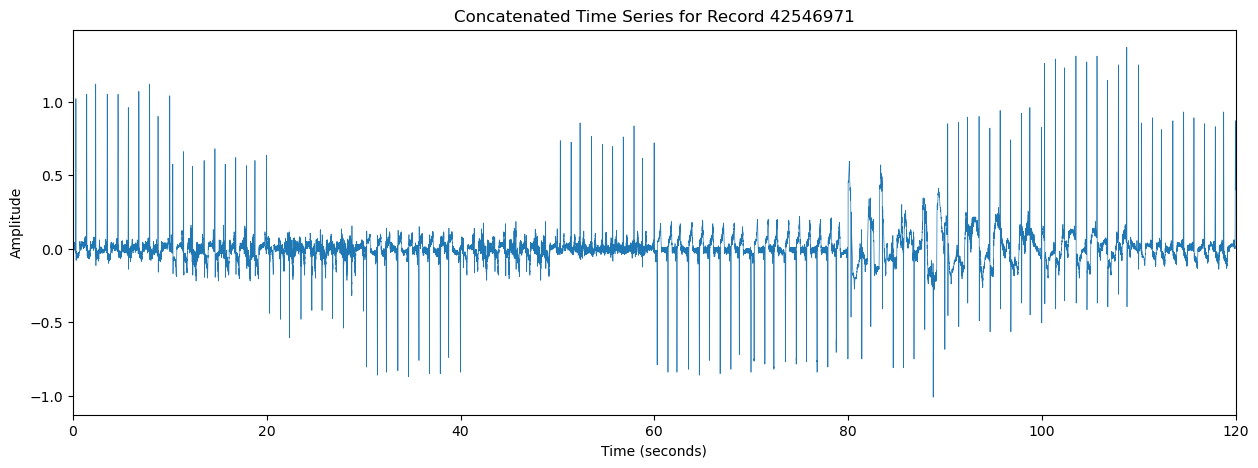

In [120]:

#Plot the first complete concatenated time series
first_record = list(timeseries_dict.keys())[0]
ts_data = timeseries_dict[first_record]
time_axis = np.arange(ts_data['total_length']) / ts_data['fs']
plt.figure(figsize=(15, 5))
plt.plot(time_axis, ts_data['signal'], linewidth=0.5)
plt.title(f"Concatenated Time Series for Record {first_record}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, ts_data['duration_seconds'] * ts_data['num_channels'])
plt.show()

# Time Series Understanding

Given a time series, it is interesting to understand the behaviour of the it; to do so we can check for some particular informations:
- **Trends**
- **Seasonality**
- **Cyclicity**

## Noise removal

### Rolling window approach

The first idea to remove noise in the time series is to use a rolling window (with a defeault value of 5), and smooth the curve. 

In [121]:
# Remove noise in the time series by applying a rolling window average filter
def moving_average(signal, window_size=5):
    """
    Apply moving average filter to a numpy array signal.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Input signal
    window_size : int
        Size of the moving average window
        
    Returns:
    --------
    pandas.Series
        Filtered signal with NaN at edges
    """
    # Convert to pandas Series for rolling window operations
    signal_series = pd.Series(signal)
    
    # Standardize: (x - mean) / std
    standardized = (signal_series - signal_series.mean()) / signal_series.std()
    
    # Apply rolling window average
    filtered = standardized.rolling(window=window_size, center=True).mean()
    
    return filtered

def moving_std(signal, window_size=5):
    """
    Apply moving standard deviation filter to a numpy array signal.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Input signal
    window_size : int
        Size of the moving std window
        
    Returns:
    --------
    pandas.Series
        Filtered signal with NaN at edges
    """
    # Convert to pandas Series for rolling window operations
    signal_series = pd.Series(signal)
    
    # Standardize: (x - mean) / std
    standardized = (signal_series - signal_series.mean()) / signal_series.std()
    
    # Apply rolling window standard deviation
    filtered = standardized.rolling(window=window_size, center=True).std()
    
    return filtered


### Low/High-Pass and Band-Pass filters

Another option is to use *Low-Pass*, *High-Pass* and *Band-Pass* filters to remove the noise on ECG signals.
- **Low-Pass filter**: A Low-Pass filter (LPF) is a filter that passes signals with a frequency lower than a selected cutoff frequency and attenuates signals with frequencies higher than the cutoff frequency.
- **High-Pass filter**: A High-Pass filter (HPF) is an electronic filter that passes signals with a frequency higher than a certain cutoff frequency and attenuates signals with frequencies lower than the cutoff frequency.
- **Band-Pass filter**: A Band-Pass filter allows through components in a specified band of frequencies, called its passband but blocks components with frequencies above or below this band. This contrasts with a high-pass filter, which allows through components with frequencies above a specific frequency, and a low-pass filter, which allows through components with frequencies below a specific frequency.

In [122]:
def low_pass_filter(signal, fs, cutoff=30, order=5):
    """
    Apply a low-pass Butterworth filter to the signal.

    Parameters:
    signal : numpy.ndarray
        Input signal
    fs : float
        Sampling frequency
    cutoff : float
        Cutoff frequency of the filter
    order : int
        Order of the filter
    Returns:
    numpy.ndarray
        Filtered signal
    """
    # Calculate the Nyquist frequency
    nyquist = 0.5 * fs

    # Normalized cutoff frequency
    normal_cutoff = cutoff / nyquist

    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='low', analog=False)

    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal

def high_pass_filter(signal, fs, cutoff=0.5, order=5):
    """
    Apply a high-pass Butterworth filter to the signal.

    Parameters:
    signal : numpy.ndarray
        Input signal
    fs : float
        Sampling frequency
    cutoff : float
        Cutoff frequency of the filter
    order : int
        Order of the filter
    Returns:
    numpy.ndarray
        Filtered signal
    """
    # Calculate the Nyquist frequency
    nyquist = 0.5 * fs

    # Normalized cutoff frequency
    normal_cutoff = cutoff / nyquist

    # Get the filter coefficients
    b, a = butter(order, normal_cutoff, btype='high', analog=False)

    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal

def band_pass_filter(signal, fs, lowcut=0.5, highcut=30, order=5):
    """
    Apply a band-pass Butterworth filter to the signal.

    Parameters:
    signal : numpy.ndarray
        Input signal
    fs : float
        Sampling frequency
    lowcut : float
        Low cutoff frequency of the filter
    highcut : float
        High cutoff frequency of the filter
    order : int
        Order of the filter
    Returns:
    numpy.ndarray
        Filtered signal
    """
    # Calculate the Nyquist frequency
    nyquist = 0.5 * fs

    # Normalized cutoff frequencies
    low = lowcut / nyquist
    high = highcut / nyquist

    # Get the filter coefficients
    b, a = butter(order, [low, high], btype='band')

    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal


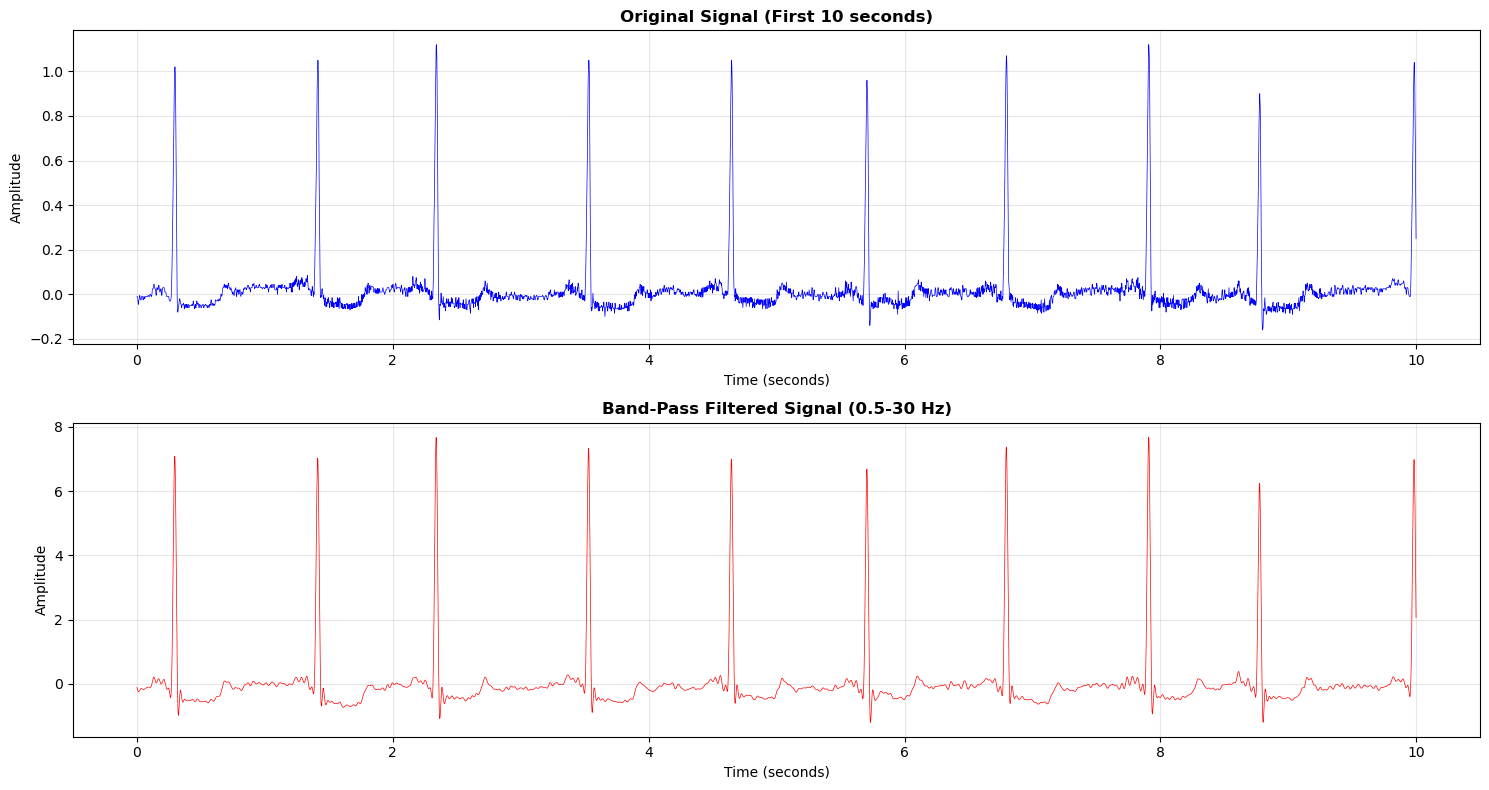

In [123]:
scaler = StandardScaler()
filtered_signal_bp = band_pass_filter(scaler.fit_transform(ts_data['signal'].reshape(-1, 1)).flatten(), fs=ts_data['fs'], lowcut=0.5, highcut=30, order=5)

# Plot comparison for first 10 seconds
fs = ts_data['fs']
samples_10s = int(10 * fs)
time_10s = np.arange(samples_10s) / fs

plt.figure(figsize=(15, 8), dpi=100)

# Original signal
plt.subplot(2, 1, 1)
plt.plot(time_10s, ts_data['signal'][:samples_10s], linewidth=0.5, color='blue')
plt.title('Original Signal (First 10 seconds)', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

# Filtered signal
plt.subplot(2, 1, 2)
plt.plot(time_10s, filtered_signal_bp[:samples_10s], linewidth=0.5, color='red')
plt.title('Band-Pass Filtered Signal (0.5-30 Hz)', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

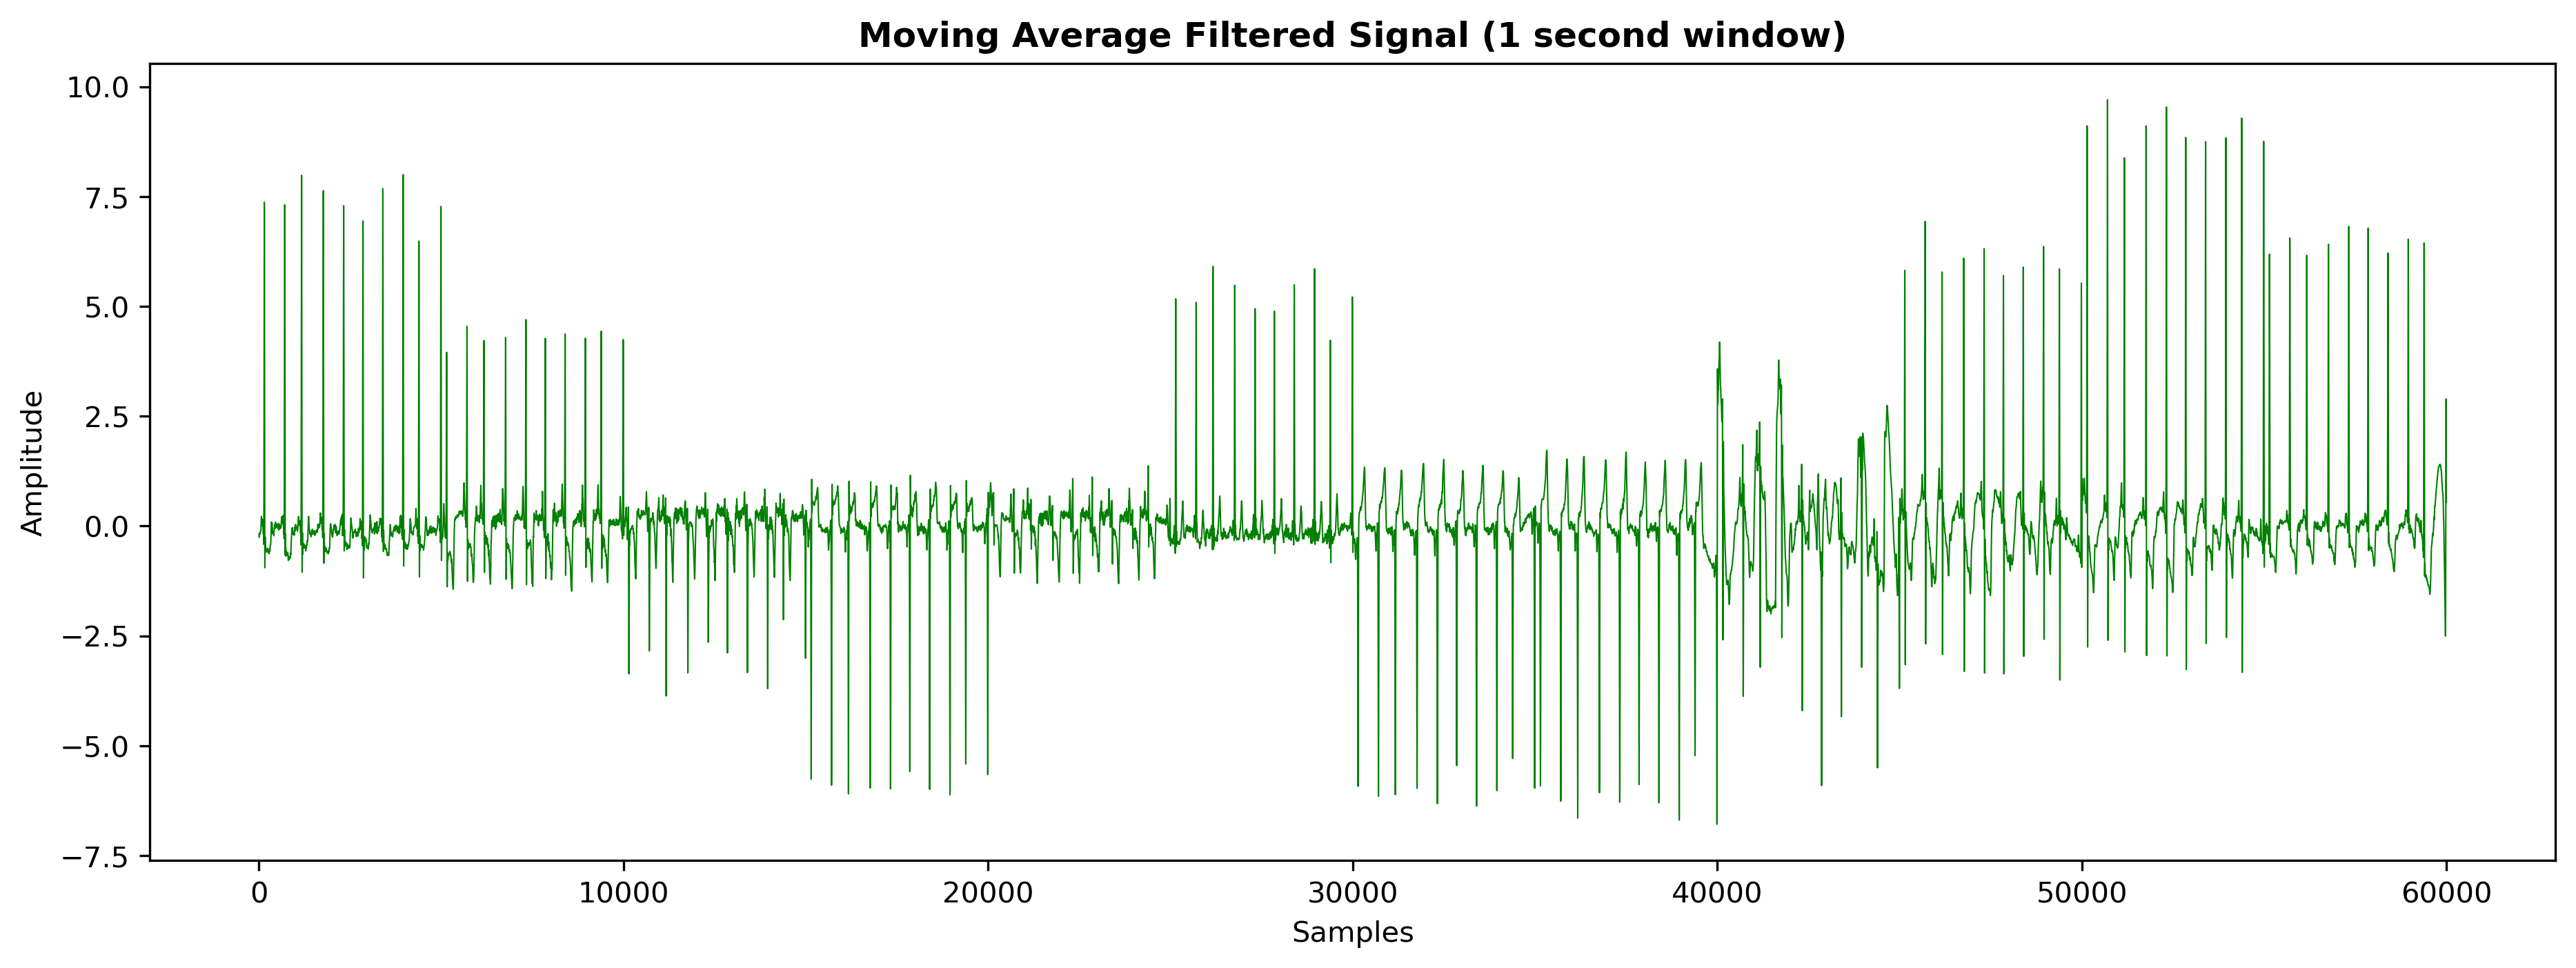

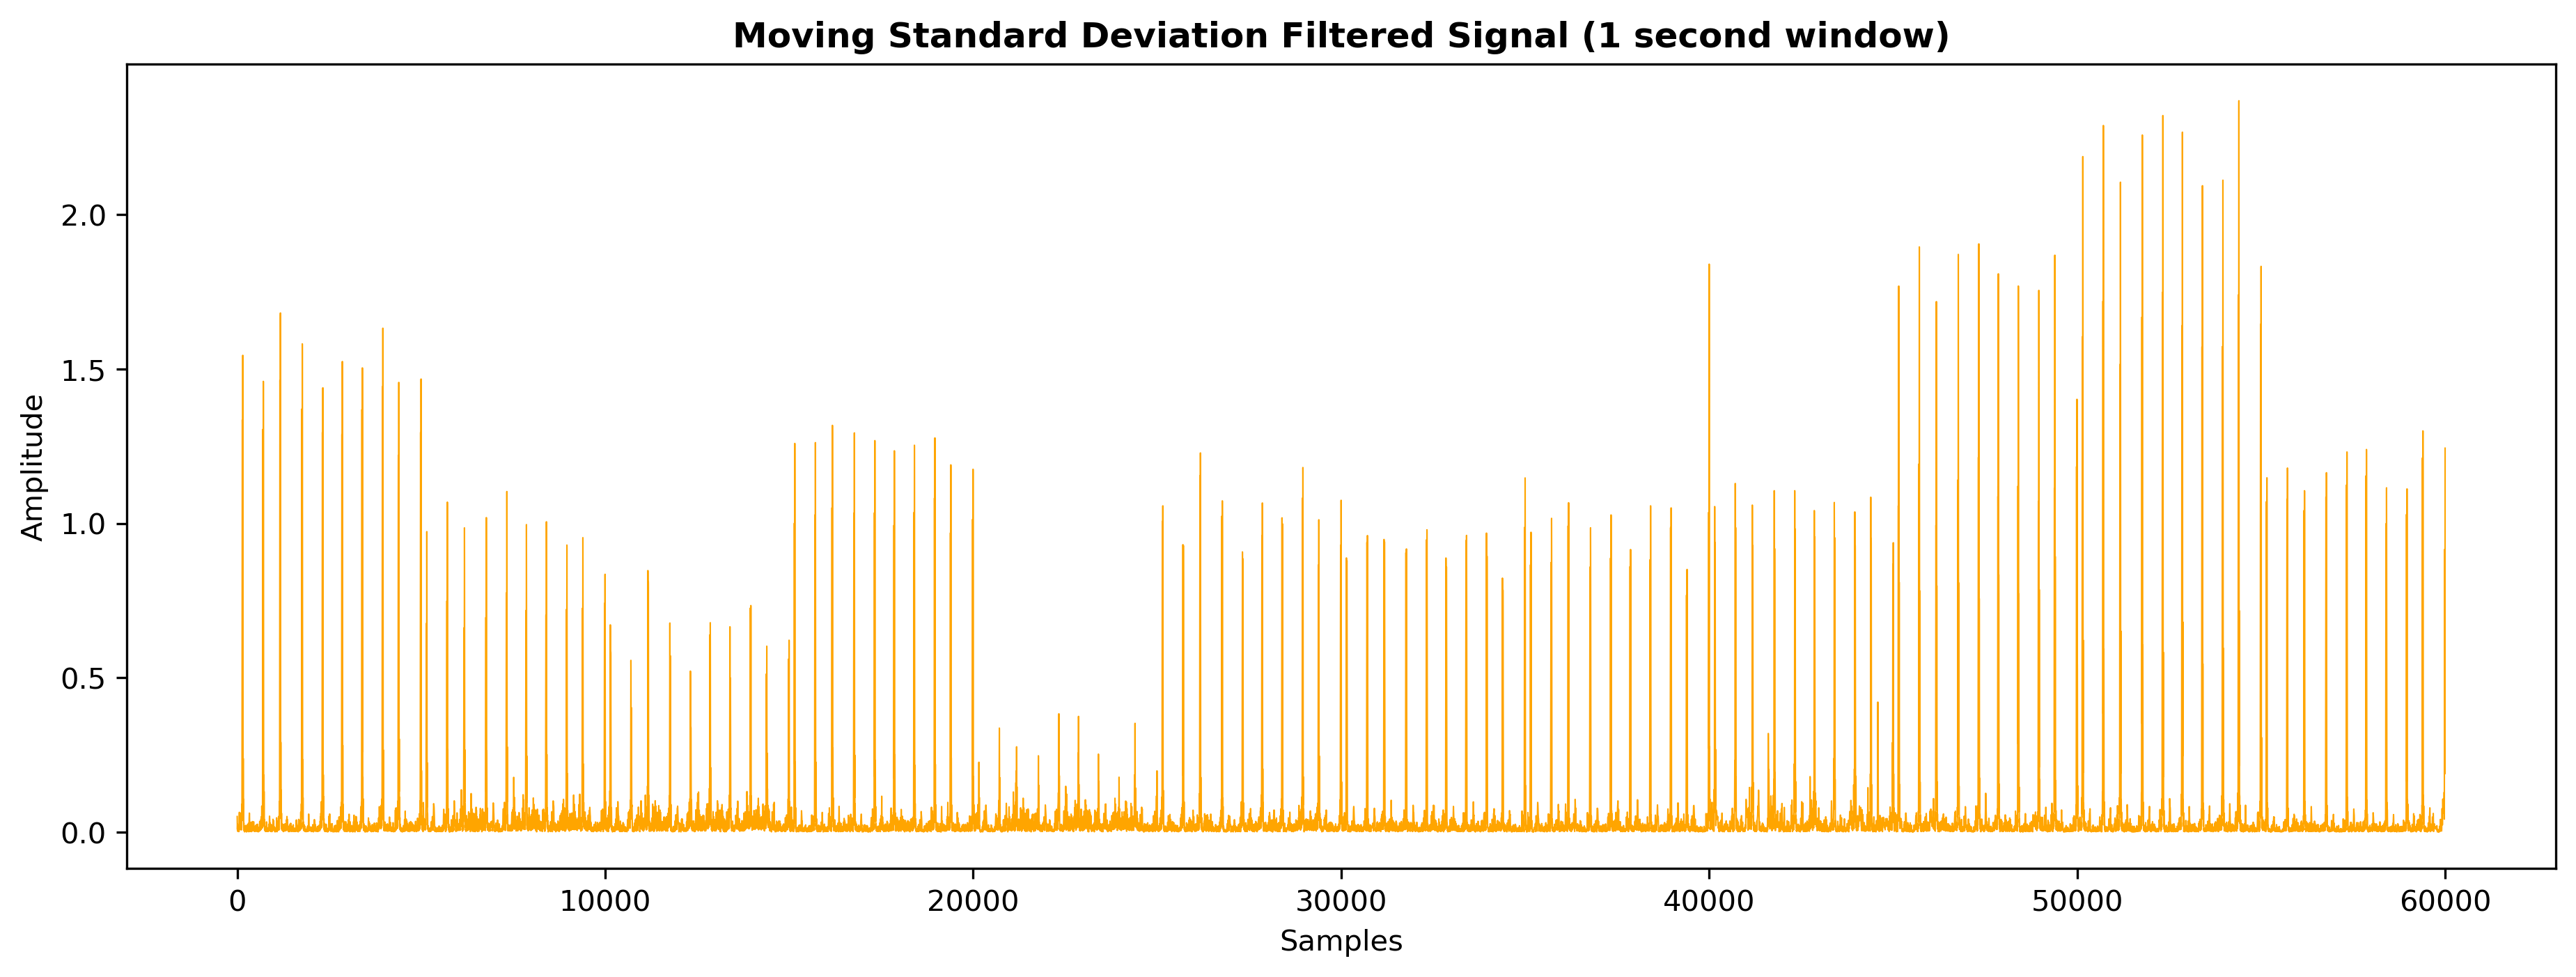

In [124]:
# Getting the mean of the series uisng the window linked to the frequency
moving_avg_signal = moving_average(filtered_signal_bp, window_size=5)
plt.figure(figsize=(15, 5), dpi=300)
plt.plot(moving_avg_signal, linewidth=0.5, color='green')
plt.title('Moving Average Filtered Signal (1 second window)', fontweight='bold')
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.show()

# Getting the std of the series uisng the window linked to the frequency
moving_std_signal = moving_std(filtered_signal_bp, window_size=5)
plt.figure(figsize=(15, 5), dpi=300)
plt.plot(moving_std_signal, linewidth=0.5, color='orange')
plt.title('Moving Standard Deviation Filtered Signal (1 second window)', fontweight='bold')
plt.xlabel('Samples')
plt.ylabel('Amplitude')
plt.show()

Having cancelled the noise from the signal, we can now check for seasonality using the auto-correlation method.

In [125]:
from statsmodels.tsa.stattools import acf
from scipy.signal import find_peaks

fs = ts_data['fs']  # e.g., 125 Hz

# Cover 3-5 complete heartbeat cycles
# For heart rate range 40-120 bpm (0.67-2 Hz)
max_cycles = 5
min_heart_rate_hz = 0.67  # 40 bpm
MAX_LAGS = int(max_cycles * fs / min_heart_rate_hz)

print(f"MAX_LAGS: {MAX_LAGS} samples ({MAX_LAGS/fs:.1f} seconds)")

# Compute and plot ACF for the filtered signal
lag_acf = acf(filtered_signal_bp, fft=True, nlags=MAX_LAGS)

MAX_LAGS: 3731 samples (7.5 seconds)


In [126]:
# Find peaks in the ACF
peaks, _ = find_peaks(lag_acf, height=0)

if len(peaks) > 1:
    # First peak is at lag 0, second peak gives the fundamental period
    fundamental_lag = peaks[1]
    fundamental_period_seconds = fundamental_lag / fs
    estimated_heart_rate_bpm = 60 / fundamental_period_seconds

    print(f"Estimated Heart Rate: {estimated_heart_rate_bpm:.2f} bpm (Fundamental Period: {fundamental_period_seconds:.2f} seconds)")
else:
    print("Not enough peaks found in the ACF to estimate heart rate.")

Estimated Heart Rate: 69.12 bpm (Fundamental Period: 0.87 seconds)


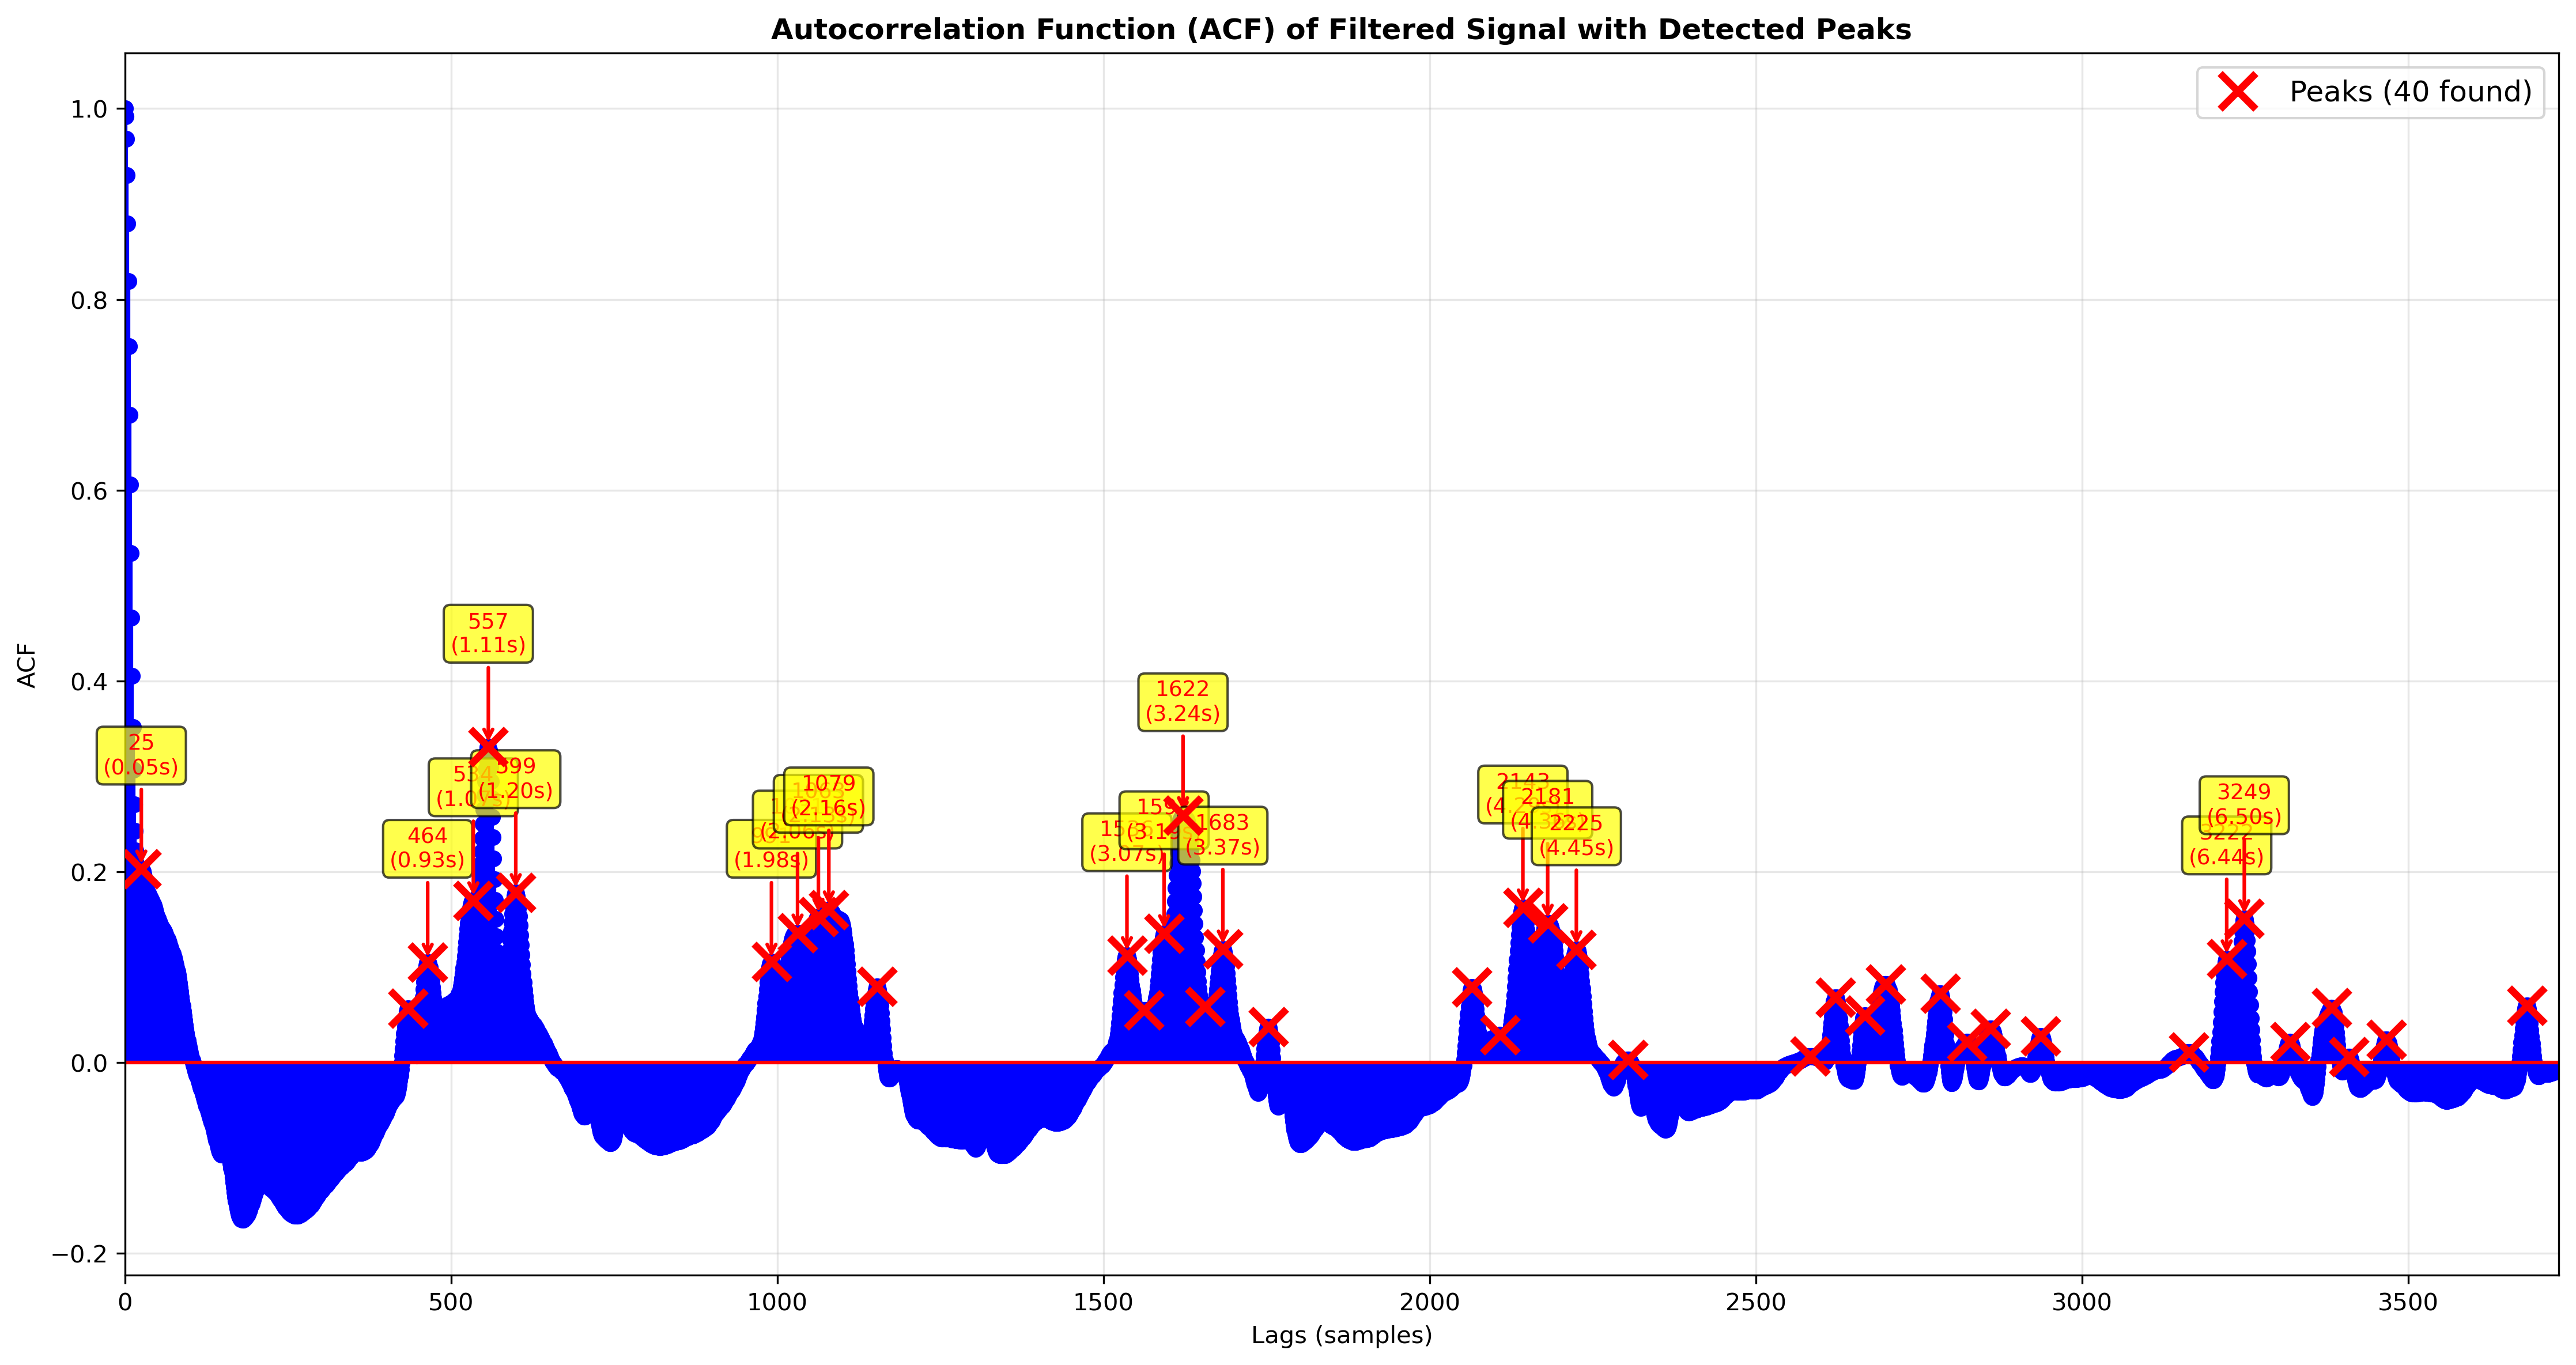


Detected Peaks in ACF
Peak #   Lag        Time (s)     Heart Rate      ACF Value 
----------------------------------------------------------------------
1        25         0.050        1200.0          0.2032    
2        434        0.868        69.1            0.0568    
3        464        0.928        64.7            0.1055    
4        534        1.068        56.2            0.1700    
5        557        1.114        53.9            0.3310    
6        599        1.198        50.1            0.1785    
7        991        1.982        30.3            0.1056    
8        1031       2.062        29.1            0.1362    
9        1063       2.126        28.2            0.1527    
10       1079       2.158        27.8            0.1604    
11       1153       2.306        26.0            0.0796    
12       1536       3.072        19.5            0.1124    
13       1562       3.124        19.2            0.0549    
14       1593       3.186        18.8            0.1354    
15    

In [127]:
plt.figure(figsize=(15, 8), dpi=300)

# Plot stem first (in background)
plt.stem(range(len(lag_acf)), lag_acf, linefmt='b-', markerfmt='bo', basefmt='r-')

# Plot peaks on top with larger, more visible markers
if len(peaks) > 0:
    plt.plot(peaks, lag_acf[peaks], "x", markersize=15, markeredgewidth=3, 
             label=f"Peaks ({len(peaks)} found)", color='red', zorder=5)
    
    # Annotate the first few significant peaks
    for i, peak in enumerate(peaks):
        if lag_acf[peak] > 0.1:  # Only annotate significant peaks
            plt.annotate(f'{peak}\n({peak/fs:.2f}s)', 
                        xy=(peak, lag_acf[peak]), 
                        xytext=(peak, lag_acf[peak] + 0.1),
                        ha='center',
                        fontsize=9,
                        color='red',
                        bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                        arrowprops=dict(arrowstyle='->', color='red', lw=1.5))

plt.title('Autocorrelation Function (ACF) of Filtered Signal with Detected Peaks', fontweight='bold')
plt.xlabel('Lags (samples)')
plt.ylabel('ACF')
plt.grid(True, alpha=0.3)
plt.xlim(0, MAX_LAGS)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# Print peak information
if len(peaks) > 0:
    print(f"\n{'='*70}")
    print(f"Detected Peaks in ACF")
    print(f"{'='*70}")
    print(f"{'Peak #':<8} {'Lag':<10} {'Time (s)':<12} {'Heart Rate':<15} {'ACF Value':<10}")
    print(f"{'-'*70}")
    for i, peak in enumerate(peaks, 1): 
        time_s = peak / fs
        bpm = 60 * fs / peak if peak > 0 else 0
        print(f"{i:<8} {peak:<10} {time_s:<12.3f} {bpm:<15.1f} {lag_acf[peak]:<10.4f}")
    print(f"{'='*70}\n")
else:
    print("No peaks detected in ACF")

### Triple Exponential Smoothing (Holt-Winters method)

In [128]:
def hw_method(series, seasonal_periods, trend='add', seasonal='add'):
    """
    Apply Holt-Winters Exponential Smoothing to a time series.
    
    Parameters:
    -----------
    series : array-like
        Input time series data
    seasonal_periods : int
        Number of periods in a complete seasonal cycle
    trend : str
        Type of trend component ('add' or 'mul')
    seasonal : str
        Type of seasonal component ('add' or 'mul')
    
    Returns:
    --------
    fitted_model : ExponentialSmoothing results object
        Fitted Holt-Winters model
    """
    model = ExponentialSmoothing(
        series,
        trend=trend,
        seasonal=seasonal,
        seasonal_periods=seasonal_periods
    )
    fit_model = model.fit()
    return fit_model


def plot_hw_decomposition(series, fitted):
    # Extract Holt-Winters internal components
    level = fitted.level
    trend = fitted.trend
    seasonal = fitted.season
    fittedvalues = fitted.fittedvalues
    
    # Remainder (error)
    remainder = series - fittedvalues

    # ----- Plot -----
    fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True, dpi = 300)
    
    # 1. Original time series
    axes[0].plot(series, color="black")
    axes[0].set_title("Time series (data)")
    
    # 2. Seasonal component
    axes[1].plot(seasonal, color="teal")
    axes[1].set_title("Seasonal patterns")
    
    # 3. Trend component
    axes[2].plot(trend, color="red")
    axes[2].set_title("General tendencies (trend)")
    
    # 4. Remainder
    axes[3].plot(remainder, color="green")
    axes[3].set_title("Error / Remainder")

    plt.xlabel("Time")
    plt.tight_layout()
    plt.show()

Optimal seasonal periods (fundamental lag): 434
Series length: 5000
Train set: 4500 samples (90.0%)
Test set: 500 samples (10.0%)
Fundamental lag: 434

Seasonal candidates: 15 (range: 431-445)
Total parameter combinations to evaluate: 540

  ✓ Iteration 2: Val SSE = 1537.9519 (Best so far)
  ✓ Iteration 6: Val SSE = 591.0412 (Best so far)
  ✓ Iteration 12: Val SSE = 560.2786 (Best so far)
  ✓ Iteration 50: Val SSE = 543.6131 (Best so far)
  ✓ Iteration 74: Val SSE = 522.9663 (Best so far)
  ✓ Iteration 86: Val SSE = 522.1800 (Best so far)

Grid Search Summary
Total combinations evaluated: 90
Failed convergences: 360
Success rate: 20.0%
Time elapsed: 33.35 seconds
Average time per model: 370.56 ms

Top 10 Best Models:
   trend seasonal  seasonal_periods  damped_trend use_boxcox     val_sse         mape
28   add      add             445.0         False       None  522.179953  1170.064732
24   add      add             443.0         False       None  522.966338  1408.535399
16   add      a

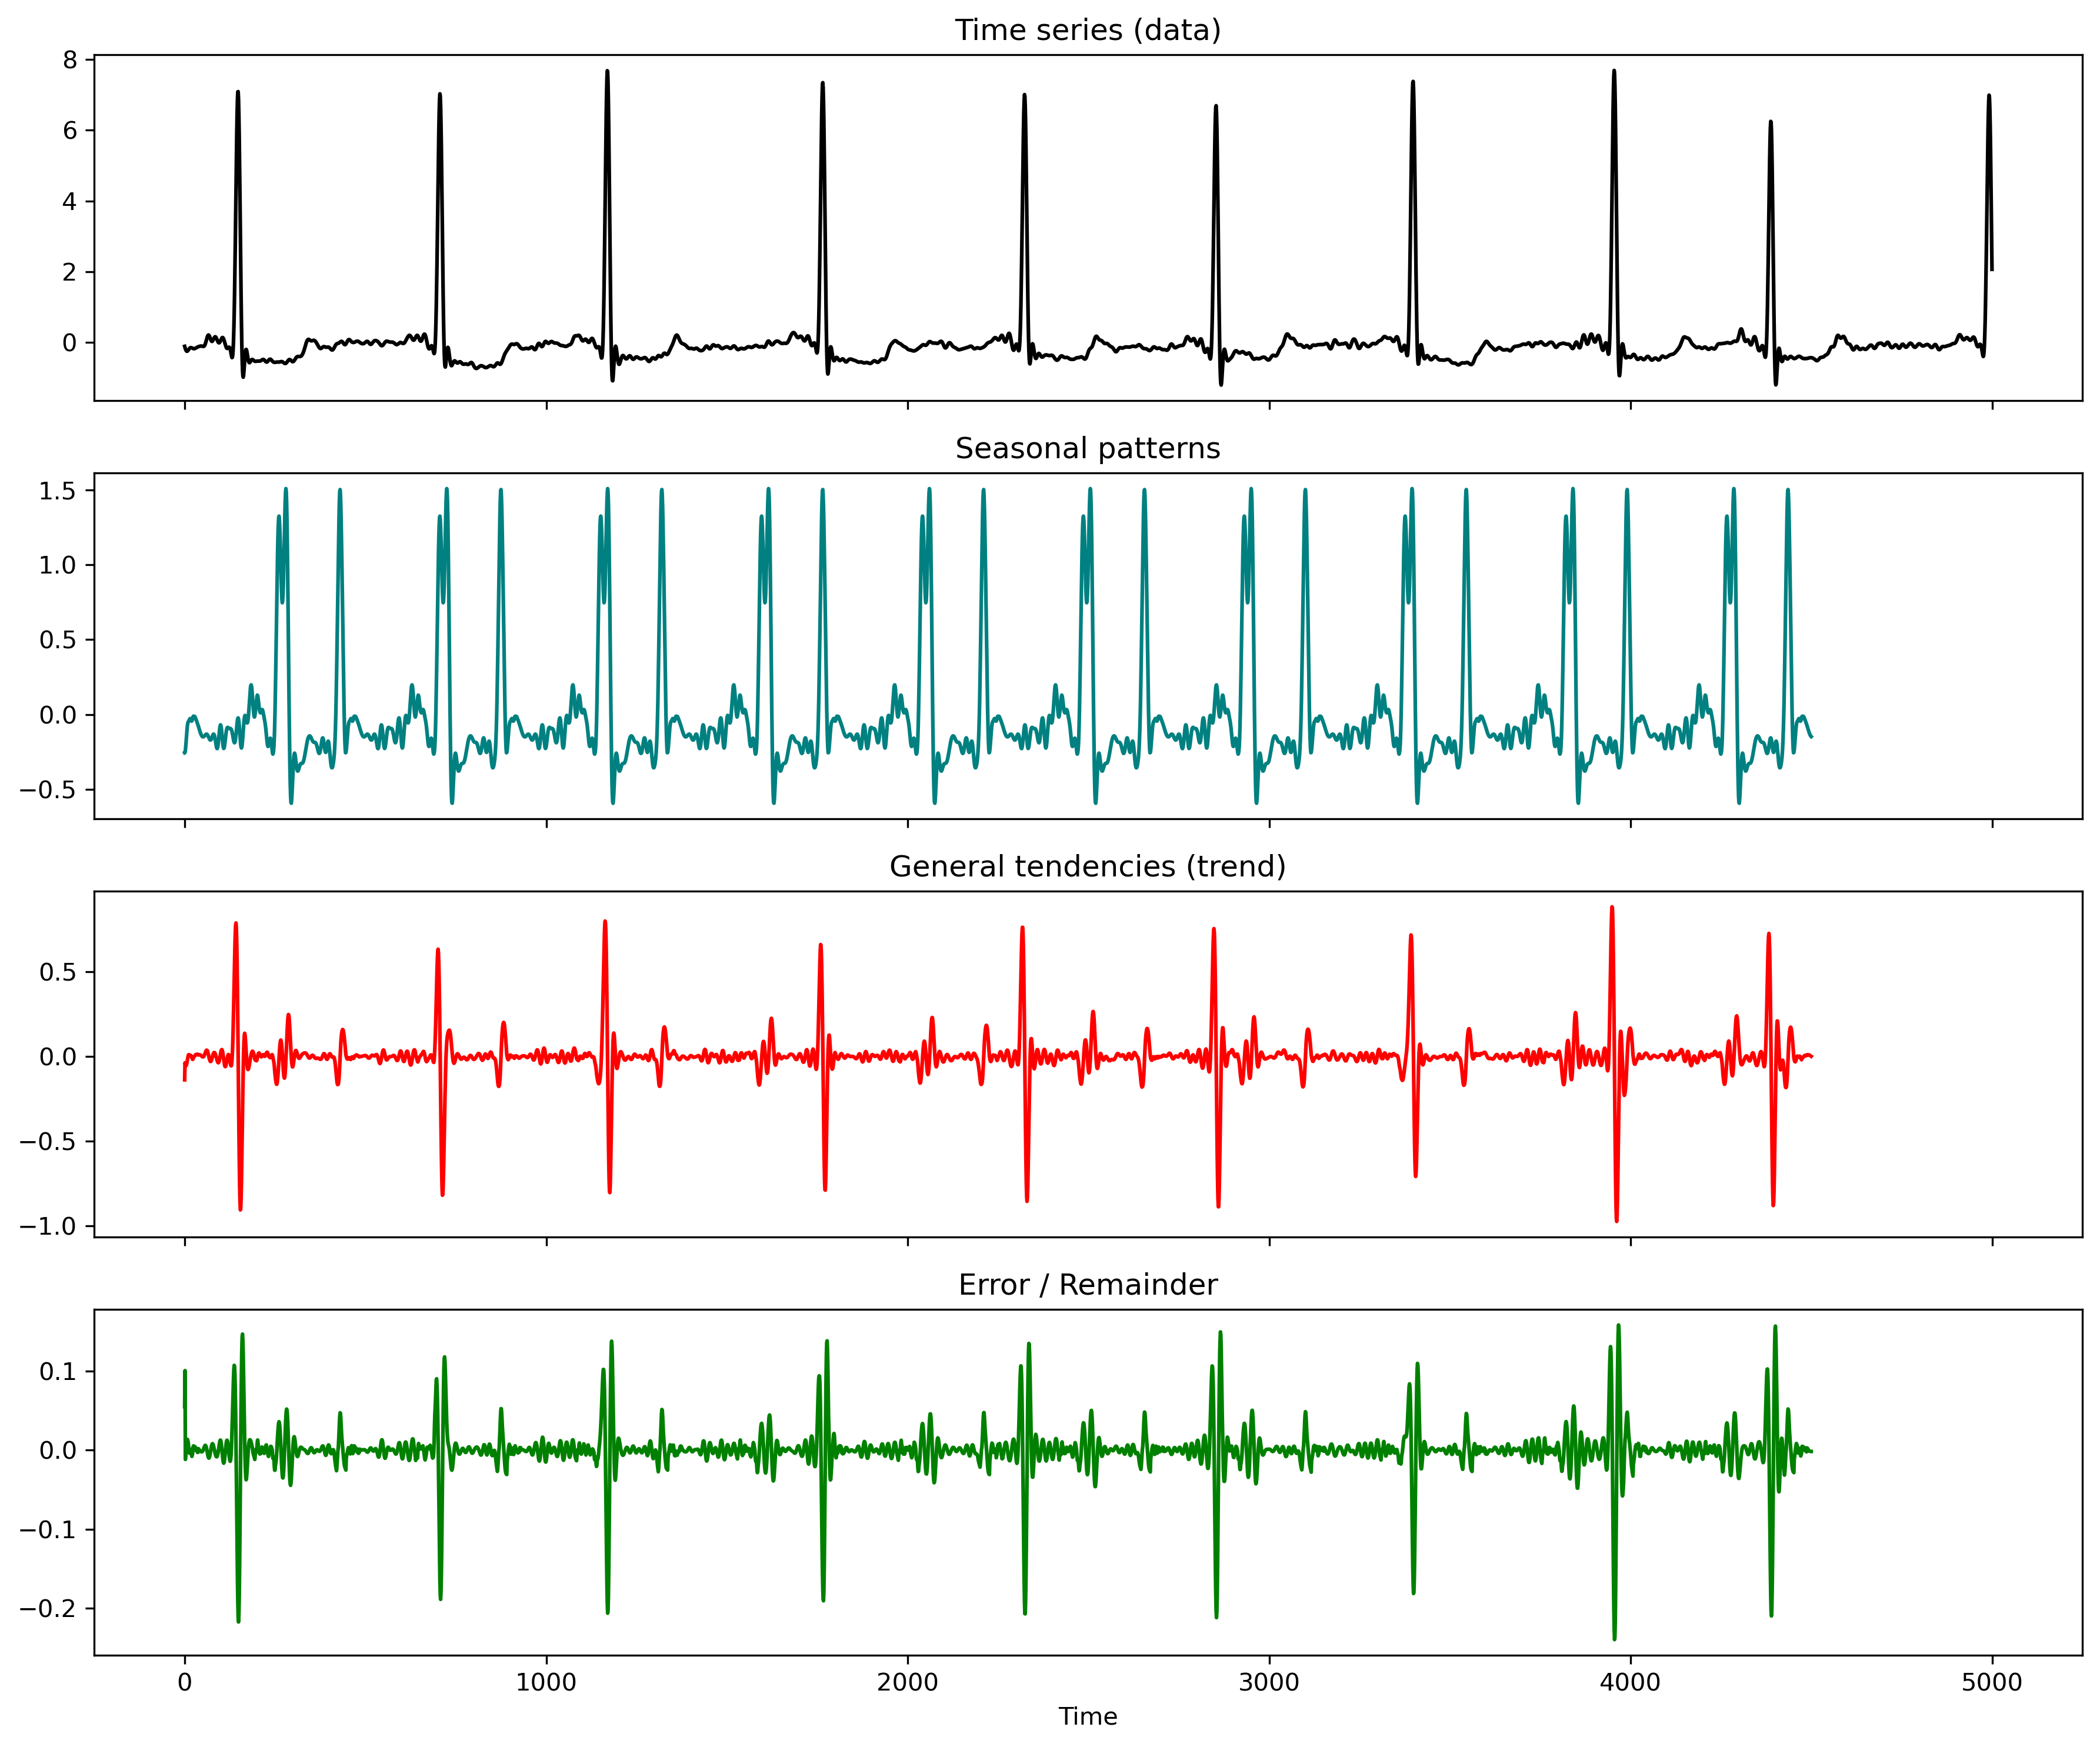

In [129]:
def perform_holt_winters_grid_search(series, fundamental_lag, train_ratio=0.9, verbose=True):
    """
    Perform Holt-Winters grid search on a time series.
    
    Parameters:
    -----------
    series : pandas.Series or numpy.ndarray
        Input time series to fit
    fundamental_lag : int
        Fundamental lag from ACF analysis (used to generate seasonal candidates)
    train_ratio : float
        Train/test split ratio (default: 0.9 for 90/10 split)
    verbose : bool
        Whether to print progress and results (default: True)
    
    Returns:
    --------
    dict : Dictionary containing:
        - 'best_model': The best fitted ExponentialSmoothing model
        - 'best_params': Dictionary of best parameters
        - 'results_df': DataFrame with all search results sorted by validation SSE
        - 'train_set': Training data used
        - 'test_set': Test data used
        - 'metrics': Dictionary with search metrics (time, convergences, etc.)
    """
    from sklearn.model_selection import ParameterGrid
    import warnings
    import time
    
    # Convert to pandas Series if needed
    if not isinstance(series, pd.Series):
        series = pd.Series(series, dtype=float)
    else:
        series = series.copy()
    
    # Train/test split
    split_idx = int(train_ratio * len(series))
    train_set = series.iloc[:split_idx]
    test_set = series.iloc[split_idx:]
    
    if verbose:
        print(f"Series length: {len(series)}")
        print(f"Train set: {len(train_set)} samples ({train_ratio:.1%})")
        print(f"Test set: {len(test_set)} samples ({1-train_ratio:.1%})")
        print(f"Fundamental lag: {fundamental_lag}\n")
    
    # Generate seasonal candidates around fundamental lag
    seasonal_candidates = sorted({
        max(2, int(fundamental_lag + shift))
        for shift in range(-3, 12)
    })
    
    # Parameter grid
    params_grid = {
        'trend': ['add', 'mul', None],
        'seasonal': ['add', 'mul', None],
        'damped_trend': [False, True],
        'seasonal_periods': seasonal_candidates,
        'use_boxcox': ['log', None],
    }
    
    total_combinations = len(list(ParameterGrid(params_grid)))
    if verbose:
        print(f"Seasonal candidates: {len(seasonal_candidates)} (range: {seasonal_candidates[0]}-{seasonal_candidates[-1]})")
        print(f"Total parameter combinations to evaluate: {total_combinations}\n")
    
    # Grid search
    search_results = []
    best_model = None
    best_score = np.inf
    best_params = None
    failed_count = 0
    start_time = time.time()
    
    for idx, params in enumerate(ParameterGrid(params_grid), 1):
        # Skip invalid combos early
        if params['trend'] is None and params['damped_trend']:
            continue
        if params['seasonal'] is None:
            params['seasonal_periods'] = None
        elif params['seasonal_periods'] < 2:
            continue
        
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", category=ConvergenceWarning)
            try:
                model = ExponentialSmoothing(
                    train_set,
                    trend=params['trend'],
                    seasonal=params['seasonal'],
                    seasonal_periods=params['seasonal_periods'],
                    damped_trend=params['damped_trend'],
                    initialization_method='estimated'
                )
                fitted = model.fit(
                    optimized=True,
                    use_boxcox=params['use_boxcox']
                )
                
                # Forecast and compute validation SSE
                val_forecast = fitted.forecast(steps=len(test_set))
                val_sse = float(np.sum((val_forecast.values - test_set.values) ** 2))
                
                # Handle MAPE calculation safely
                try:
                    mape = np.mean(np.abs((test_set.values - val_forecast.values) / test_set.values)) * 100
                except:
                    mape = np.nan
                
                metrics = {
                    'trend': params['trend'],
                    'seasonal': params['seasonal'],
                    'seasonal_periods': params['seasonal_periods'],
                    'damped_trend': params['damped_trend'],
                    'use_boxcox': params['use_boxcox'],
                    'train_sse': fitted.sse,
                    'train_aic': fitted.aic,
                    'val_sse': val_sse,
                    'mape': mape,
                }
                search_results.append((metrics, fitted))
                
                if val_sse < best_score:
                    best_score = val_sse
                    best_model = fitted
                    best_params = params.copy()
                    if verbose:
                        print(f"  ✓ Iteration {idx}: Val SSE = {val_sse:.4f} (Best so far)")
                    
            except Exception as e:
                failed_count += 1
                continue
    
    elapsed_time = time.time() - start_time
    
    if not search_results:
        raise RuntimeError("No Holt-Winters configuration converged.")
    
    # Sort results by validation SSE
    results_df = pd.DataFrame([m for m, _ in search_results]).sort_values('val_sse')
    
    if verbose:
        print(f"\n{'='*90}")
        print(f"Grid Search Summary")
        print(f"{'='*90}")
        print(f"Total combinations evaluated: {len(search_results)}")
        print(f"Failed convergences: {failed_count}")
        print(f"Success rate: {len(search_results)/(len(search_results)+failed_count)*100:.1f}%")
        print(f"Time elapsed: {elapsed_time:.2f} seconds")
        print(f"Average time per model: {elapsed_time/len(search_results)*1000:.2f} ms")
        print(f"{'='*90}\n")
        
        print("Top 10 Best Models:")
        display_cols = ['trend', 'seasonal', 'seasonal_periods', 'damped_trend', 'use_boxcox', 'val_sse', 'mape']
        print(results_df.head(10)[display_cols].to_string())
        
        print(f"\n{'='*90}")
        print(f"Best Model Parameters:")
        print(f"{'='*90}")
        best_row = results_df.iloc[0]
        print(f"  Trend:           {best_row['trend']}")
        print(f"  Seasonal:        {best_row['seasonal']}")
        print(f"  Seasonal Period: {int(best_row['seasonal_periods']) if pd.notna(best_row['seasonal_periods']) else 'N/A'}")
        print(f"  Damped Trend:    {best_row['damped_trend']}")
        print(f"  Box-Cox:         {best_row['use_boxcox']}")
        print(f"  Train SSE:       {best_row['train_sse']:.4f}")
        print(f"  Train AIC:       {best_row['train_aic']:.4f}")
        print(f"  Validation SSE:  {best_row['val_sse']:.4f}")
        print(f"  MAPE:            {best_row['mape']:.2f}%")
        print(f"{'='*90}\n")
    
    return {
        'best_model': best_model,
        'best_params': best_params,
        'results_df': results_df,
        'train_set': train_set,
        'test_set': test_set,
        'metrics': {
            'total_evaluated': len(search_results),
            'failed_convergences': failed_count,
            'success_rate': len(search_results)/(len(search_results)+failed_count),
            'elapsed_time': elapsed_time,
            'best_val_sse': best_score,
        }
    }

# Extract first 10 seconds of the signal
fs = ts_data['fs']
samples_10s = int(10 * fs)
signal_10s = filtered_signal_bp[:samples_10s]


optimal_seasonal_periods = peaks[1]
print(f"Optimal seasonal periods (fundamental lag): {optimal_seasonal_periods}")
filtered_series = pd.Series(signal_10s, dtype=float)

hw_results = perform_holt_winters_grid_search(
    filtered_series,
    fundamental_lag=optimal_seasonal_periods,
    train_ratio=0.9,
    verbose=True
)
plot_hw_decomposition(filtered_series, hw_results['best_model'])



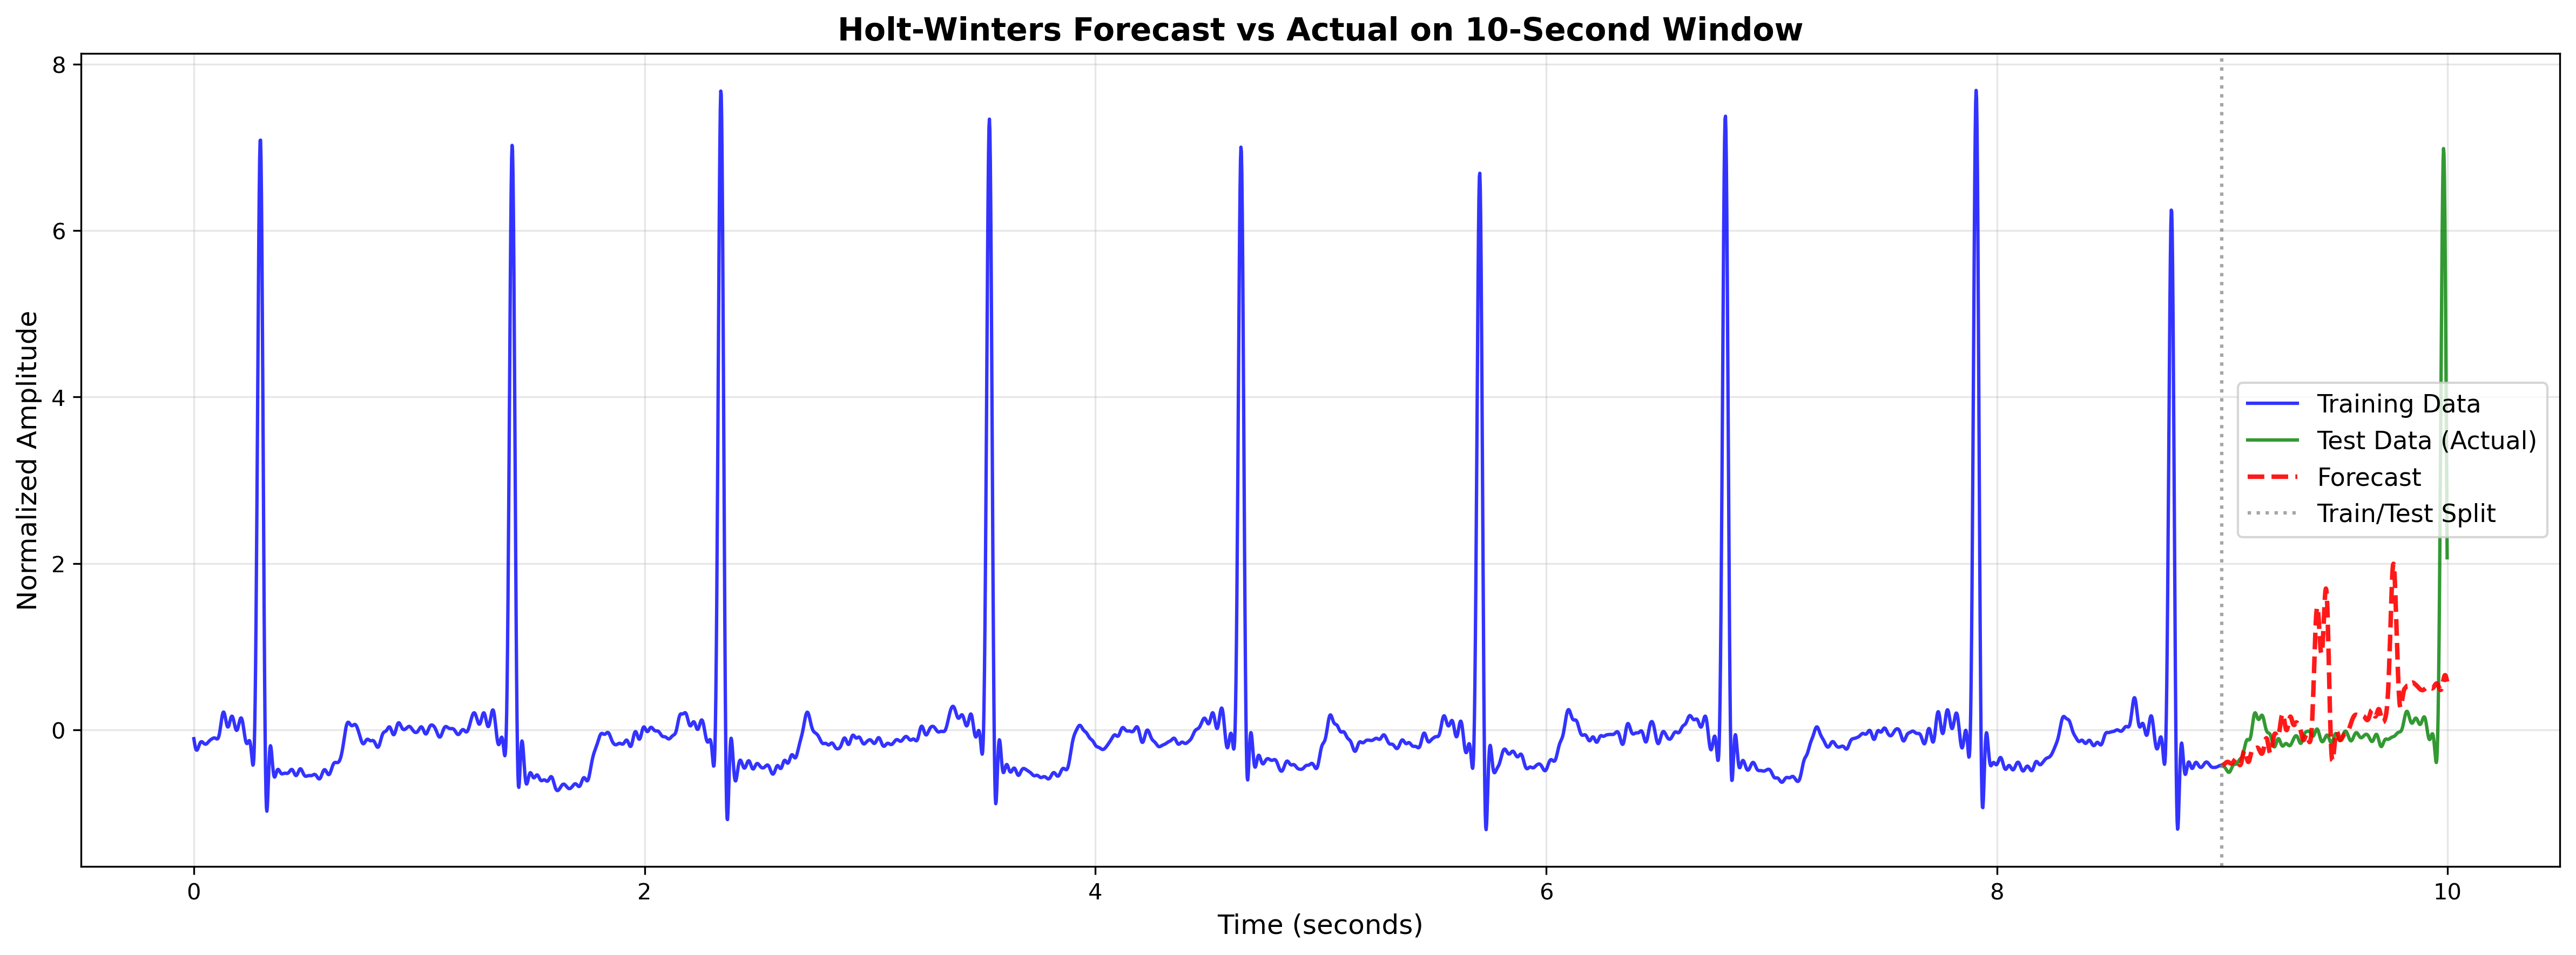


Forecast Performance Metrics on Test Set
  MAE (Mean Absolute Error):  0.512562
  RMSE (Root Mean Sq. Error): 1.021939
  MAPE (Mean Absolute % Err): 1170.06%
  SSE (Sum of Squared Error): 522.179953
  Test set size:              500 samples
  Forecast horizon:           500 steps

Residuals Analysis:
  Mean:     -0.127328
  Std Dev:  1.013976
  Min:      -2.077353
  Max:      6.381123



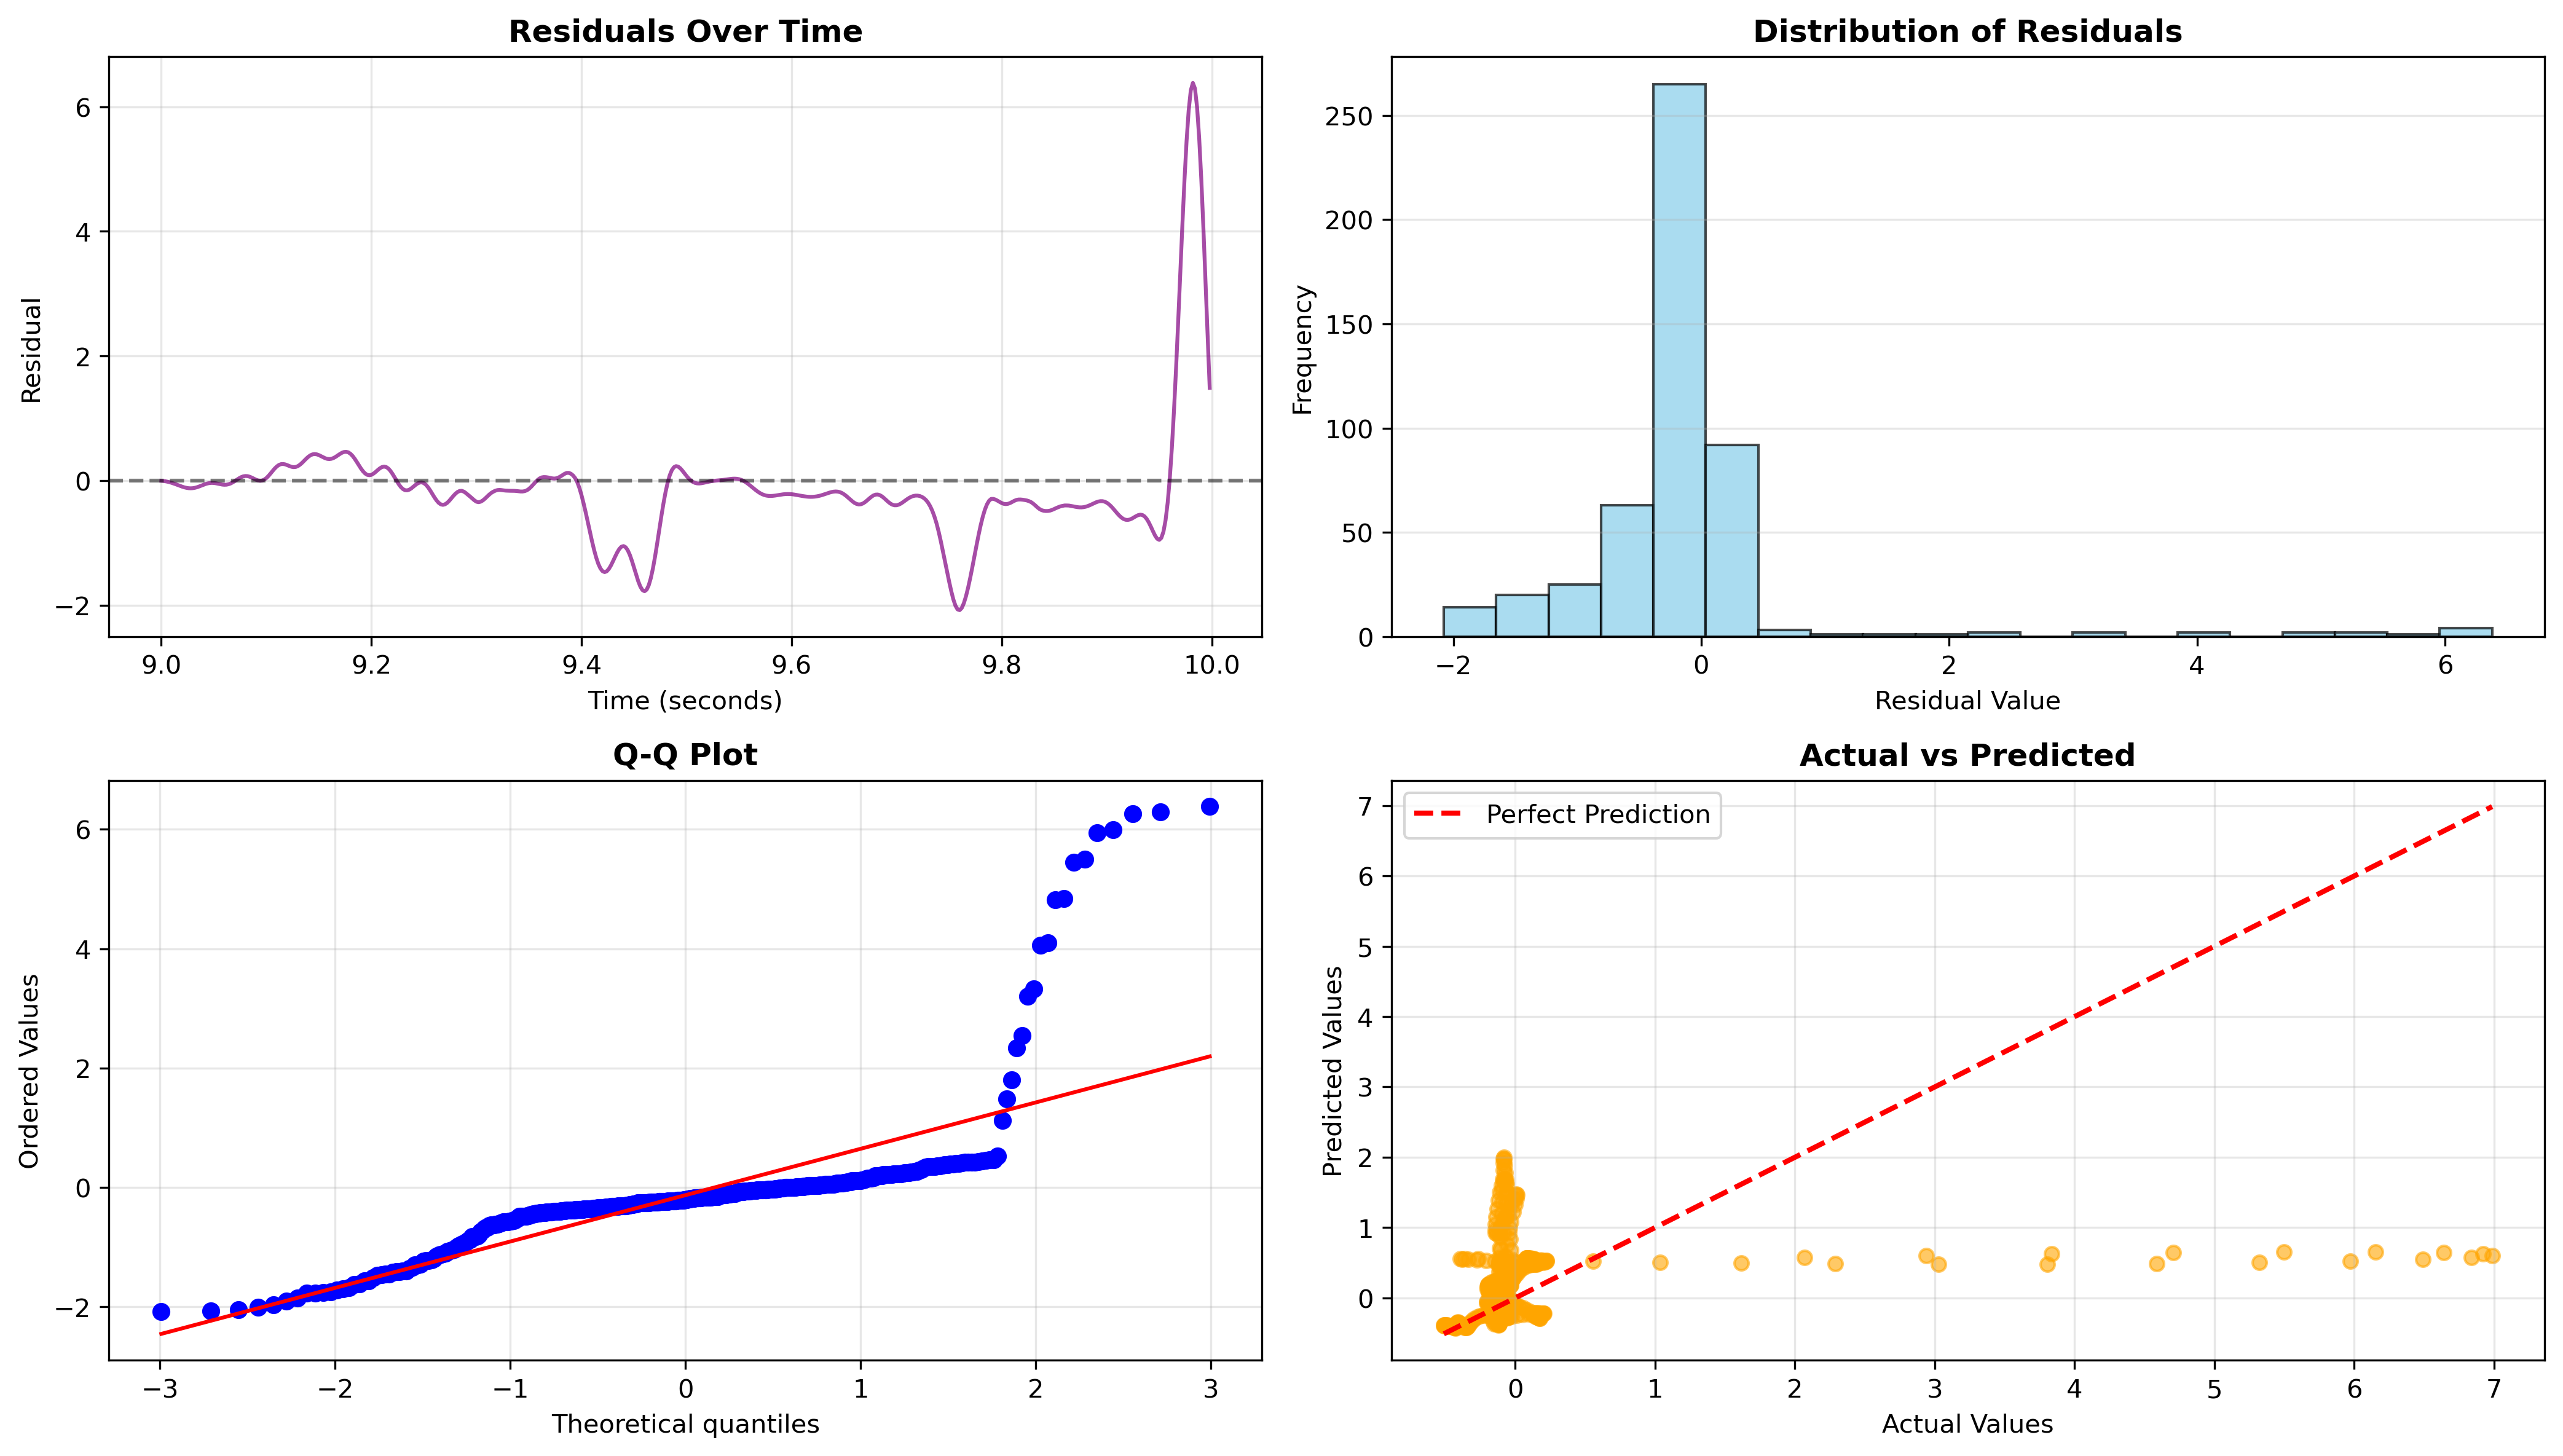

Forecast results stored in 'forecast_results' dictionary


In [130]:
# Forecast using the best model
fitted_model = hw_results['best_model']
train_set = hw_results['train_set']
test_set = hw_results['test_set']
fs = ts_data['fs']

# Generate forecast on test set
forecast = fitted_model.forecast(steps=len(test_set))

# Create time axis for visualization
time_axis_full = np.arange(len(filtered_series)) / fs
time_axis_train = time_axis_full[:len(train_set)]
time_axis_test = time_axis_full[len(train_set):]

# Plot: Training, Test, and Forecast
plt.figure(figsize=(16, 6), dpi=300)

# Plot training data
plt.plot(time_axis_train, train_set.values, label='Training Data', color='blue', linewidth=1.5, alpha=0.8)

# Plot test data (actual)
plt.plot(time_axis_test, test_set.values, label='Test Data (Actual)', color='green', linewidth=1.5, alpha=0.8)

# Plot forecast
plt.plot(time_axis_test, forecast.values, label='Forecast', color='red', linestyle='--', linewidth=2, alpha=0.9)

# Add vertical line to mark train/test split
plt.axvline(x=time_axis_train[-1], color='gray', linestyle=':', alpha=0.7, linewidth=1.5, label='Train/Test Split')

plt.title('Holt-Winters Forecast vs Actual on 10-Second Window', fontweight='bold', fontsize=14)
plt.xlabel('Time (seconds)', fontsize=12)
plt.ylabel('Normalized Amplitude', fontsize=12)
plt.legend(fontsize=11, loc='best')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate and print forecast metrics
mae = np.mean(np.abs(forecast.values - test_set.values))
rmse = np.sqrt(np.mean((forecast.values - test_set.values) ** 2))
mape = np.mean(np.abs((forecast.values - test_set.values) / test_set.values)) * 100
sse = np.sum((forecast.values - test_set.values) ** 2)

print(f"\n{'='*70}")
print(f"Forecast Performance Metrics on Test Set")
print(f"{'='*70}")
print(f"  MAE (Mean Absolute Error):  {mae:.6f}")
print(f"  RMSE (Root Mean Sq. Error): {rmse:.6f}")
print(f"  MAPE (Mean Absolute % Err): {mape:.2f}%")
print(f"  SSE (Sum of Squared Error): {sse:.6f}")
print(f"  Test set size:              {len(test_set)} samples")
print(f"  Forecast horizon:           {len(forecast)} steps")
print(f"{'='*70}\n")

# Residuals analysis
residuals = test_set.values - forecast.values

print(f"Residuals Analysis:")
print(f"  Mean:     {np.mean(residuals):.6f}")
print(f"  Std Dev:  {np.std(residuals):.6f}")
print(f"  Min:      {np.min(residuals):.6f}")
print(f"  Max:      {np.max(residuals):.6f}")
print(f"{'='*70}\n")

# Plot residuals
fig, axes = plt.subplots(2, 2, figsize=(14, 8), dpi=300)

# Residuals over time
axes[0, 0].plot(time_axis_test, residuals, color='purple', linewidth=1.5, alpha=0.7)
axes[0, 0].axhline(y=0, color='black', linestyle='--', alpha=0.5)
axes[0, 0].set_title('Residuals Over Time', fontweight='bold')
axes[0, 0].set_xlabel('Time (seconds)')
axes[0, 0].set_ylabel('Residual')
axes[0, 0].grid(True, alpha=0.3)

# Histogram of residuals
axes[0, 1].hist(residuals, bins=20, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Distribution of Residuals', fontweight='bold')
axes[0, 1].set_xlabel('Residual Value')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Q-Q plot
from scipy import stats
stats.probplot(residuals, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title('Q-Q Plot', fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# Actual vs Predicted scatter
axes[1, 1].scatter(test_set.values, forecast.values, alpha=0.6, s=30, color='orange')
axes[1, 1].plot([test_set.values.min(), test_set.values.max()], 
                [test_set.values.min(), test_set.values.max()], 
                'r--', lw=2, label='Perfect Prediction')
axes[1, 1].set_title('Actual vs Predicted', fontweight='bold')
axes[1, 1].set_xlabel('Actual Values')
axes[1, 1].set_ylabel('Predicted Values')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Store forecast results
forecast_results = {
    'forecast': forecast,
    'actual': test_set,
    'residuals': residuals,
    'mae': mae,
    'rmse': rmse,
    'mape': mape,
    'sse': sse,
}

print("Forecast results stored in 'forecast_results' dictionary")

Due to the highly irregular behaviour of the ECGs, Holter-Winters method can fail to get seasonality. In the specific case of ECGs, we can apply the Pan-Tompkins algorithm.

### Pan-Tompkins algorithm

In [131]:
def pt_algorithm(signal, fs):
    """
    Apply the Pan-Tompkins algorithm to detect R-peaks in ECG signals.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Input ECG signal
    fs : float
        Sampling frequency
        
    Returns:
    --------
    r_peaks : numpy.ndarray
        Indices of detected R-peaks in the signal
    """
    # Step 1: Low-pass filter (0.5-30 Hz)
    lp_filtered = low_pass_filter(signal, fs, cutoff=30, order=5)

    hp_filtered = high_pass_filter(lp_filtered, fs, cutoff=0.5, order=5)
    
    # Step 2: Derivative filter
    derivative_signal = np.diff(hp_filtered)
    
    # Step 3: Squaring
    squared_signal = np.square(derivative_signal)
    
    # Step 4: Moving window integration
    window_size = int(0.150 * fs)  # 150 ms window
    integrated_signal = moving_average(squared_signal, window_size=window_size).fillna(0).values
    
    return integrated_signal

In [132]:
def QRSpeaks(signal, fs):
    """
    Detect QRS peaks (R-peaks) in Pan-Tompkins processed signal.
    
    Parameters:
    -----------
    signal : numpy.ndarray
        Integrated signal from Pan-Tompkins algorithm
    fs : float
        Sampling frequency
        
    Returns:
    --------
    peaks : numpy.ndarray
        Indices of detected R-peaks
    """
    # Use find_peaks from scipy.signal (already imported)
    peaks, _ = find_peaks(signal, height=np.mean(signal), distance=round(fs*0.200))
    return peaks

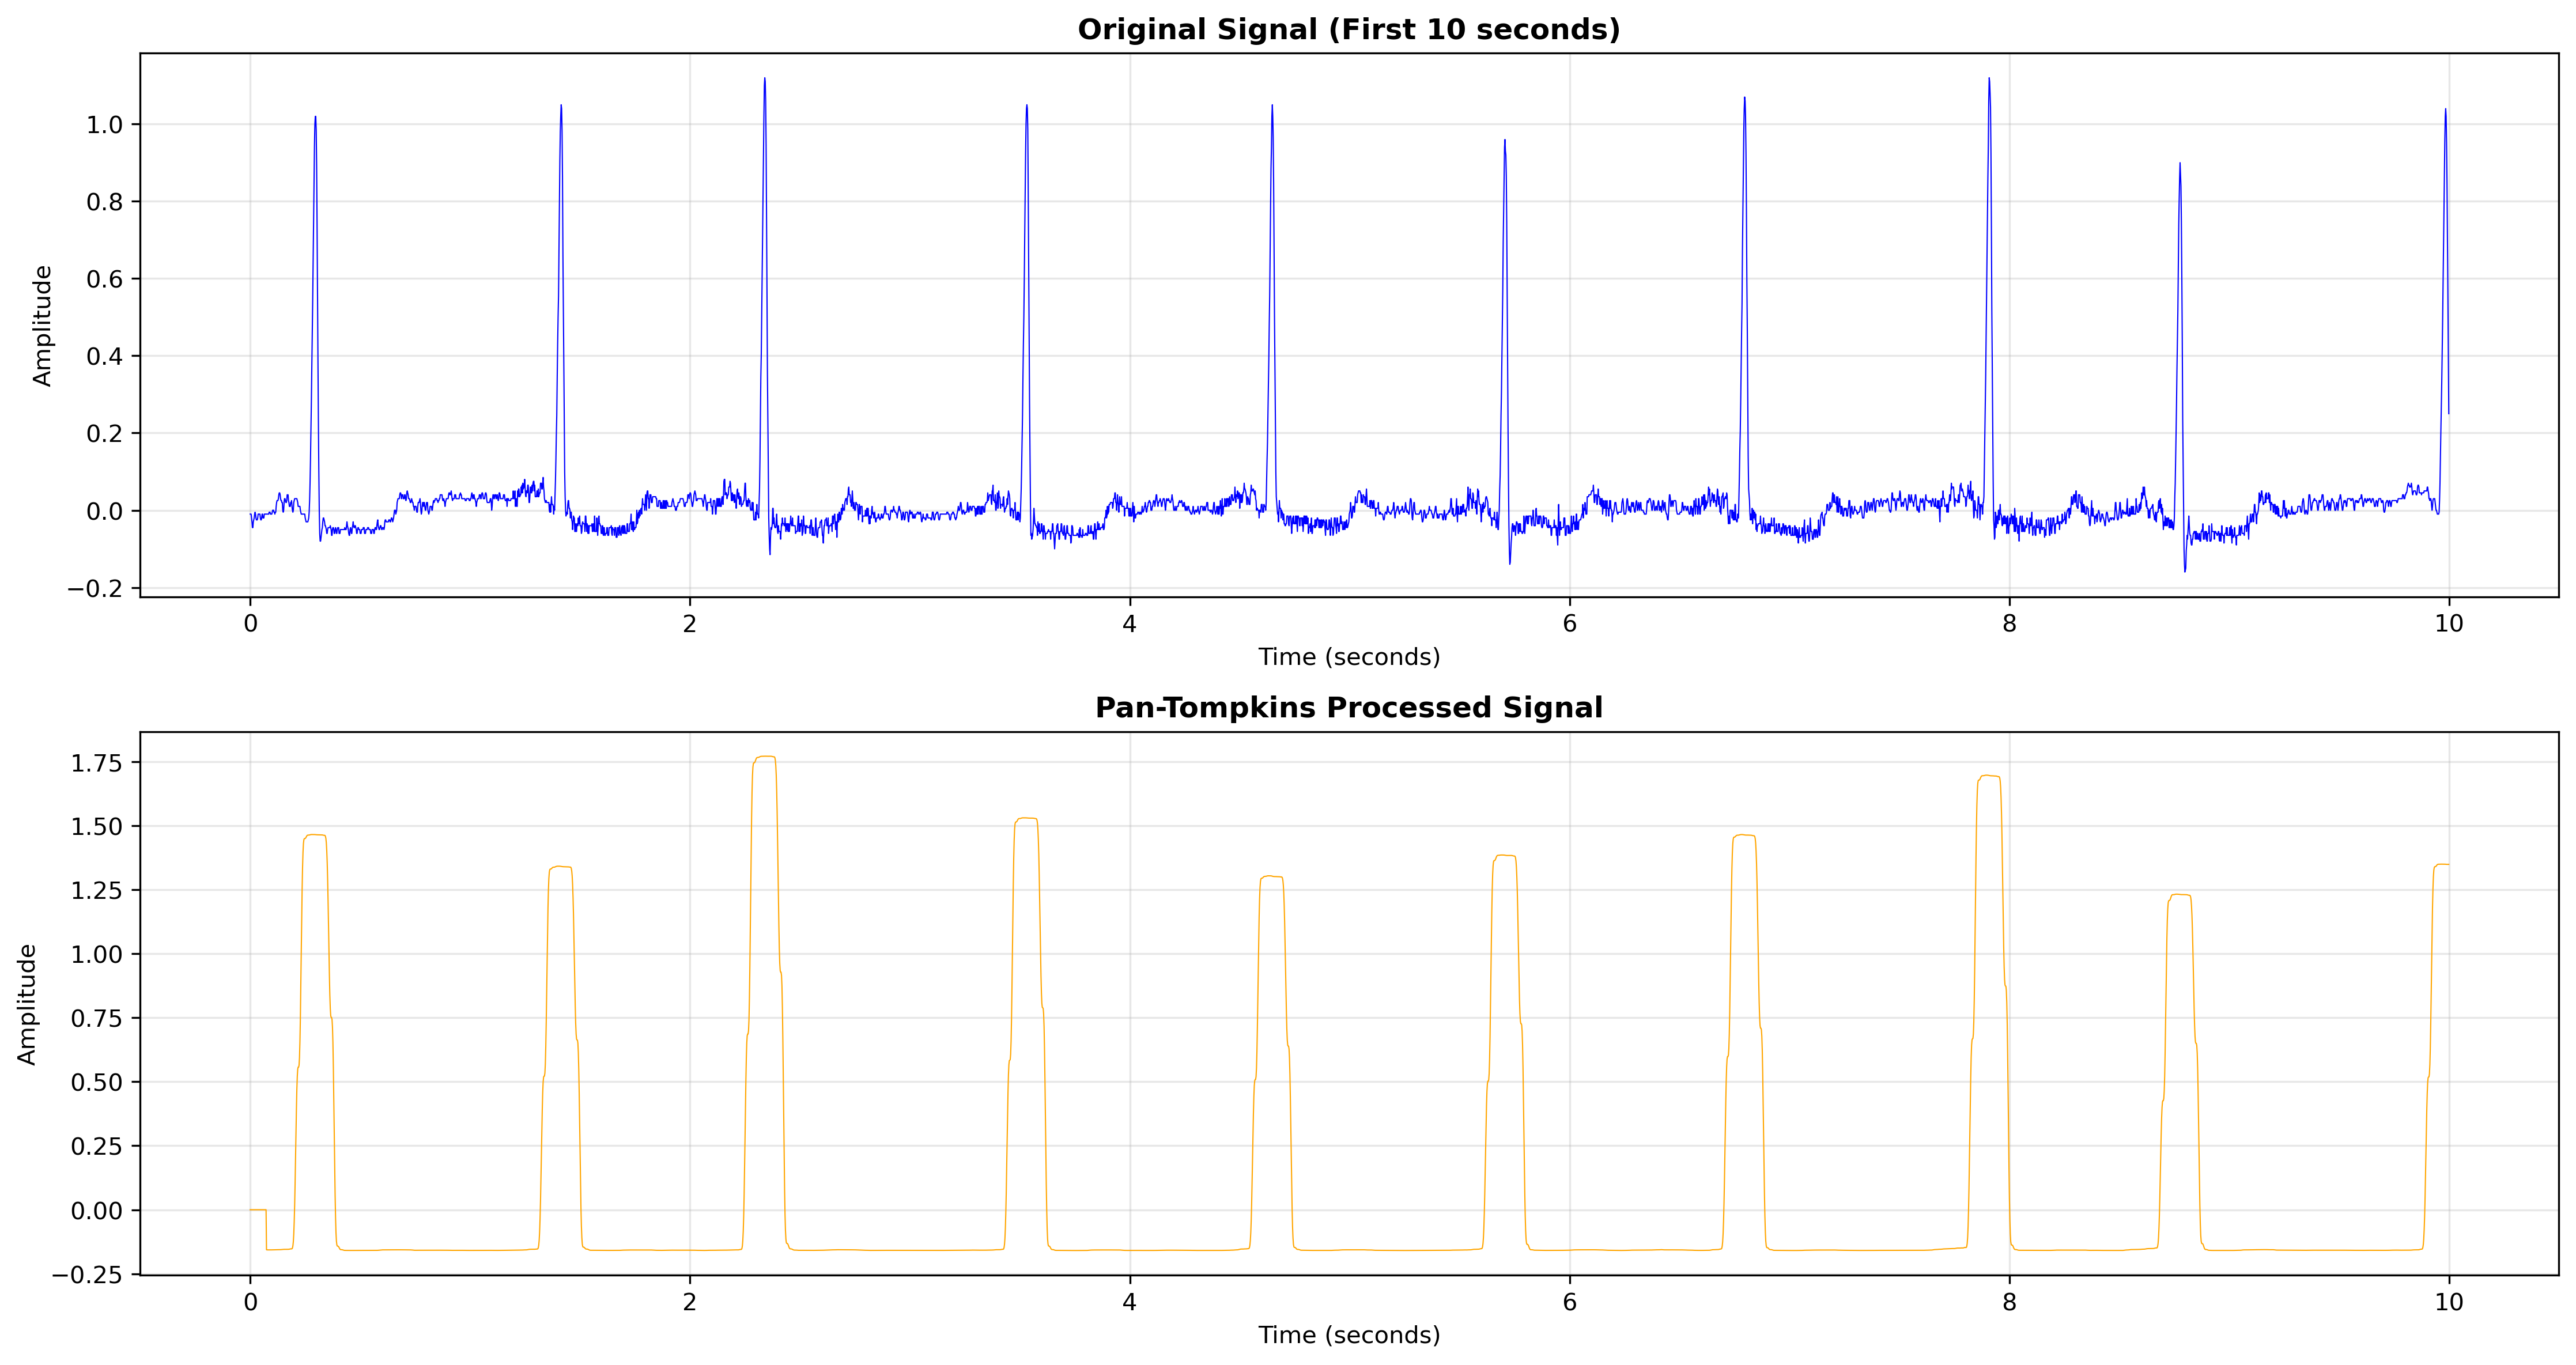

In [133]:
pt_filtered_signal = pt_algorithm(ts_data['signal'], fs=ts_data['fs'])

# Plot the Pan-Tompkins processed signal over the original signal for first 10 seconds
fs = ts_data['fs']
samples_10s = int(10 * fs)
time_10s = np.arange(samples_10s) / fs
plt.figure(figsize=(15, 8), dpi=300)
# Original signal
plt.subplot(2, 1, 1)
plt.plot(time_10s, ts_data['signal'][:samples_10s], linewidth=0.5, color='blue')
plt.title('Original Signal (First 10 seconds)', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)
# Pan-Tompkins processed signal
plt.subplot(2, 1, 2)
plt.plot(time_10s, pt_filtered_signal[:samples_10s], linewidth=0.5, color='orange')
plt.title('Pan-Tompkins Processed Signal', fontweight='bold')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Detected 110 R-peaks in the ECG signal.


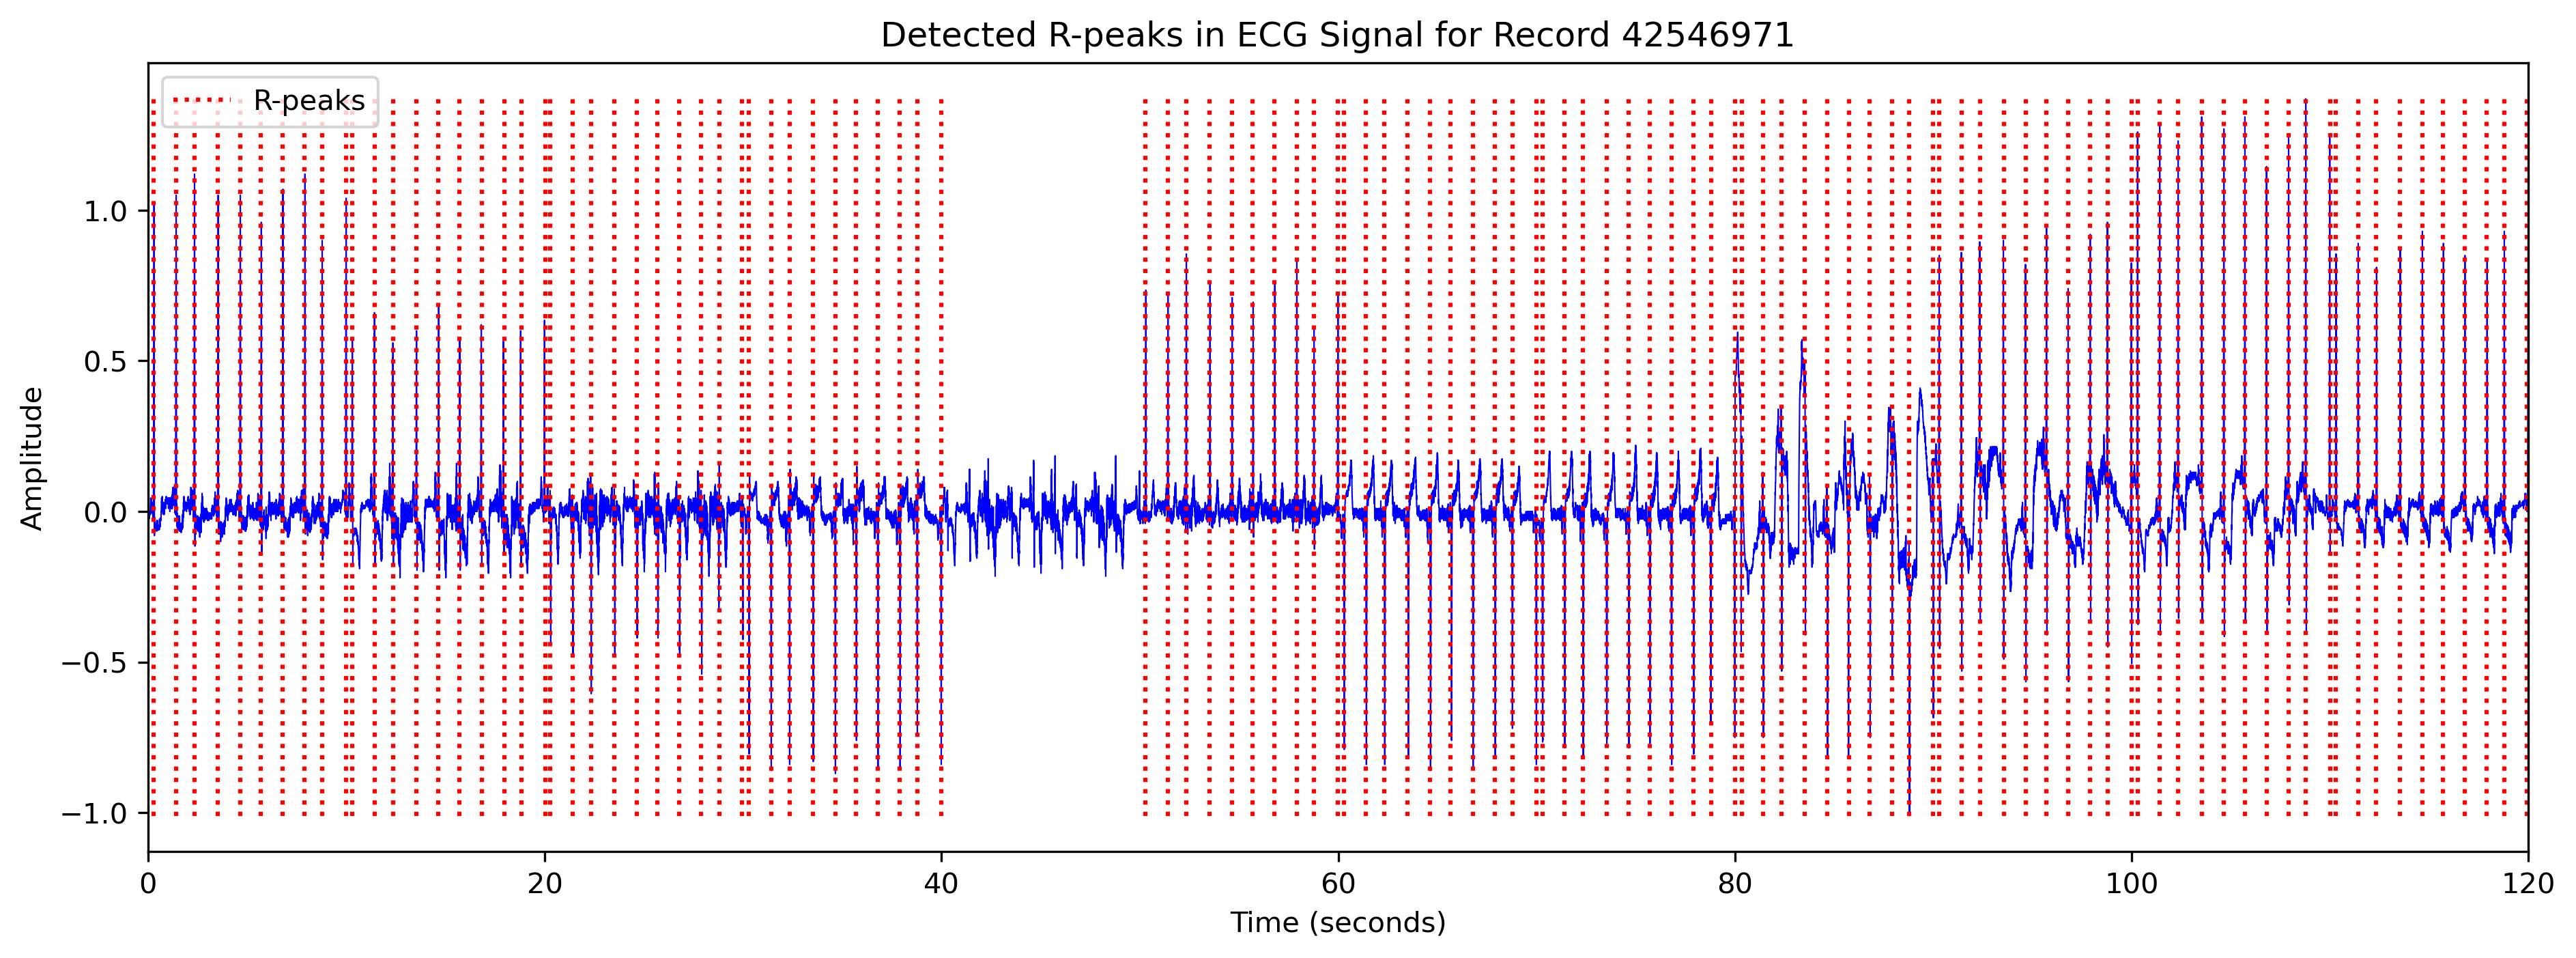

In [134]:
r_peaks = QRSpeaks(pt_filtered_signal, fs=ts_data['fs'])
print(f"Detected {len(r_peaks)} R-peaks in the ECG signal.")

# Plot detected R-peaks (vertical dotted lines) on original signal for the full duration
time_axis = np.arange(ts_data['total_length']) / ts_data['fs']
plt.figure(figsize=(15, 5), dpi=300)
plt.plot(time_axis, ts_data['signal'], linewidth=0.5, color='blue')
plt.vlines(r_peaks / ts_data['fs'], ymin=min(ts_data['signal']), ymax=max(ts_data['signal']), colors='red', linestyles='dotted', label='R-peaks')
plt.title(f"Detected R-peaks in ECG Signal for Record {first_record}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, ts_data['duration_seconds'] * ts_data['num_channels'])
plt.legend()
plt.show()
